# 03. New College: FM51 versus numerical LI-Init on 60-second rollouts

**Cross-dataset, zero-retraining evaluation.** The FM checkpoint is the *KAIST* `kaist_pooled_calibration_fm.8_topology_179/best.pt` from notebook 02, evaluated on the physical **New College RealSense IMU + Ouster IMU + Ouster LiDAR odometry** topology constructed exactly as in notebook 45. The numerical baseline pairs **Ouster IMU and Ouster LiDAR only**. Neither method is tuned using New College errors.

Two independent baseline protocols for each of ten non-overlapping 60-second intervals (12 × 5 s):

- **5-second joint:** Reoptimize rotation, gyro bias, and time offset using the *current* 5-second LiDAR/IMU measurements, carrying the previous rotation as initialization.
- **Causal expanding 5→60 seconds:** Reoptimize using all measurements seen *so far*, producing a 60-second solution only at the final timestamp. No future 60-second LiDAR increments enter earlier solutions, although the configured ±0.35 s IMU timing padding adds limited post-window IMU context.

FM processes 5-second windows at each step, using only its left-multiplicative *LiDAR rotation correction*; both IMU states and all translation/time-offset state components remain fixed. Each angle panel compares **two mean curves across the same 10 physical intervals**, with 10–90% bands and CPU/GPU-synchronized compute timing.

**Reference caveat:** The New College transforms are composed from the supplied camera/Kalibr and Ouster mount YAMLs, then optionally expressed in a fixed common Z-up frame. They are **nominal references, not independently certified ground truth**. New College clock offsets are not evaluated as ground truth. The `NC_LIDAR_EFFECTIVE_TIME_SHIFT_S` is a *chosen measurement timestamp correction*, not clock ground truth.

**Information asymmetry:** FM gets two IMUs and one LiDAR; LI-Init gets one IMU and the same LiDAR. Runtime includes per-window tokenization and model inference or numerical synchronization and optimization, but excludes loading and disk I/O.

## 1. Configuration and reproducibility

In [1]:
from pathlib import Path

RUN_NAME = "03_newcollege_fm52_vs_li_init"
NEWCOLLEGE_ROOT = Path("/mnt/d/Downloads/MobRobLab/NewCollegeDataset")
DATASET_ROOT = NEWCOLLEGE_ROOT / "01_short_experiment"
LIDAR_ODOMETRY_CSV = NEWCOLLEGE_ROOT / "lidar_odometry.csv"
REALSENSE_IMU_DIR = DATASET_ROOT / "raw_format" / "realsense_imu"
OUSTER_IMU_DIR = DATASET_ROOT / "raw_format" / "ouster_imu"
CALIBRATION_FOLDER = NEWCOLLEGE_ROOT / "04_calibration"
CALIBRATION_ZIP = NEWCOLLEGE_ROOT / "04_calibration.zip"
REALSENSE_IMU_NAME = None
OUSTER_IMU_NAME = None
OLD_PROJECT_SRC = None

# Used ONLY as a schema template for WindowBatch/metadata, never as New College measurements.
KAIST_TEMPLATE_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
KAIST_TEMPLATE_LIDAR_ROOT = KAIST_TEMPLATE_DATASET_ROOT
KAIST_TEMPLATE_SEQUENCE = "Urban38"

FM_CHECKPOINT = Path("runs/kaist_pooled_calibration_fm.9_signed_z_yaw/best.pt")
CALIBRATION_KEYS = ("imu_realsense", "imu_ouster", "lidar")
STREAM_CALIBRATION_KEYS = {"gyro": "imu_realsense", "accel": "imu_realsense", "gyro_ouster": "imu_ouster", "accel_ouster": "imu_ouster", "lidar": "lidar"}
TARGET_KEY = "lidar"
NUMERIC_IMU_KEY = "imu_ouster"  # Ouster IMU mounted on the same rigid rig as its LiDAR.

TARGET_IMU_FREQUENCY_HZ = 100.0
MAX_IMU_FILES = None
WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700
MIN_IMU_SAMPLES_PER_WINDOW = 8
MIN_LIDAR_EDGES_PER_WINDOW = 2
MAX_WINDOWS = None
MAX_IMU_SAMPLE_GAP_S = 0.5

# Retain the New College notebook 45 timestamp adjustment; ablate 0.0 separately.
NC_LIDAR_EFFECTIVE_TIME_SHIFT_S = 0.060
TAU_REALSENSE_REFERENCE_S = 0.11101  # Nominal/provisional, not timing ground truth.
TAU_OUSTER_REFERENCE_S = None
OUSTER_TAU_REFERENCE_VERIFIED = False
USE_FIXED_Z_UP = True
NEWCOLLEGE_UP_IN_CAMERA = (-0.0240, -0.9967, 0.0773)
Z_UP_YAW_DEG = 0.0
MATCH_PHYSICAL_FAULTS_ACROSS_FRAMES = True

DEVICE_NAME = "cuda" if __import__("torch").cuda.is_available() else "cpu"
MODEL_DTYPE_NAME = "float32"
RANDOM_SEED = 234567
MODEL_DROPOUT = 0.0
FM_INTEGRATION_STEPS = 16
FM_INTEGRATION_METHOD = "midpoint"
FM_ROTATION_GAIN = 1.0
FM_MAX_ROTATION_STEP_DEG = None

NUM_STARTS = 10
ROLL_OUT_S = 60.0
STEPS = int(ROLL_OUT_S / WINDOW_DURATION_S)
ANGLES_DEG = (0.0, 15.0, 30.0, 45.0, 60.0, 90.0, 120.0, 150.0, 179.0)
AXIS_SEEDS = 1
NUMERIC_IMU_PADDING_S = 0.35
NUMERIC_TIME_BOUNDS = (-0.30, 0.30)
NUMERIC_MAX_COARSE_CANDIDATES = 2
NUMERIC_FILTERING = False
NUMERIC_MAX_NFEV = 200
NUMERIC_TEMPORAL_RESIDUAL = "interpolate"
NUMERIC_MAX_LIDAR_GAP_S = 0.75
SHOW_PLOTS = True
SAVE_RESULTS = True

assert STEPS == 12 and STEPS * WINDOW_DURATION_S == ROLL_OUT_S
assert NUMERIC_IMU_PADDING_S >= max(abs(x) for x in NUMERIC_TIME_BOUNDS)

## 2. Imports, project paths, and source checks

In [5]:
import dataclasses
import sys
import zipfile
from dataclasses import replace
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from tqdm.auto import tqdm
from scipy.spatial.transform import Rotation as SciPyRotation
from scipy.integrate import trapezoid
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir() and (candidate / "src" / "baselines").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run inside nn-obs-calib with src/obscalib and src/baselines")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
if OLD_PROJECT_SRC is not None:
    sys.path.insert(0, str(Path(OLD_PROJECT_SRC).expanduser()))

from new_college_dataset import load_imus
from new_college_dataset.lidar import load_lidar_data_csv
from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, PooledCalibrationFlowConfig, CalibrationFlowIntegratorConfig, TransformerConfig, WindowingConfig
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.context import calibration_state_to_context
from obscalib.data.structures import WindowBatch
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.training.checkpoint import load_training_checkpoint

from baselines.li_init import LIInitConfig, lidar_increments_to_motion
from baselines.li_init.structures import IMUSeries, LidarIncrements
from baselines.li_init.adapters import slice_li_init_window
from baselines.li_init.rotation import solve_Rot_bias_gyro
from baselines.li_init.temporal import xcorr_temporal_init
from baselines.li_init.benchmark import rotation_error_degrees

DEVICE = torch.device(DEVICE_NAME)
MODEL_DTYPE = getattr(torch, MODEL_DTYPE_NAME)
FM_CHECKPOINT = FM_CHECKPOINT if FM_CHECKPOINT.is_absolute() else ROOT / FM_CHECKPOINT
OUTPUT_DIR = ROOT / "outputs" / "newcollege_fm_vs_li_init"
PLOTS_DIR = ROOT / "outputs" / "plots" / "newcollege_fm_vs_li_init"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

required = [REALSENSE_IMU_DIR, OUSTER_IMU_DIR, LIDAR_ODOMETRY_CSV, FM_CHECKPOINT, KAIST_TEMPLATE_DATASET_ROOT, KAIST_TEMPLATE_LIDAR_ROOT]
missing = [str(p) for p in required if not Path(p).exists()]
if missing:
    raise FileNotFoundError("Missing inputs:\n" + "\n".join(missing))
if not CALIBRATION_FOLDER.is_dir() and not CALIBRATION_ZIP.is_file():
    raise FileNotFoundError("Missing New College calibration YAML directory and archive")
print("Torch:", torch.__version__, "| device:", DEVICE)
print("New College:", NEWCOLLEGE_ROOT, "| checkpoint:", FM_CHECKPOINT)
print("Numerical reference:", NUMERIC_IMU_KEY, "+", TARGET_KEY)

Torch: 2.7.1+cu126 | device: cuda
New College: /mnt/d/Downloads/MobRobLab/NewCollegeDataset | checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.9_signed_z_yaw/best.pt
Numerical reference: imu_ouster + lidar


## 3. Load original IMU signals and LiDAR odometry
This section is adapted directly from notebook 45. In particular, its scan-boundary and +60 ms timestamp conventions are preserved; no artificial perturbations are applied to the measurements.

In [6]:
def scan_boundaries(data):
    relative = np.asarray(data.relative_poses_se3, dtype=np.float64)
    if relative.ndim != 3 or relative.shape[1:] != (4, 4):
        raise ValueError(f'Expected relative poses [N,4,4], got {relative.shape}')
    N = len(relative)
    explicit = None if data.scan_timestamps_s is None else np.asarray(data.scan_timestamps_s, dtype=np.float64)
    midpoints = np.asarray(data.timestamps_s, dtype=np.float64)
    if explicit is not None and len(explicit) == N + 1:
        times = explicit
    elif len(midpoints) == N + 1:
        times = midpoints
    elif len(midpoints) == N and N > 1:
        times = np.empty(N + 1, dtype=np.float64)
        times[1:-1] = 0.5 * (midpoints[:-1] + midpoints[1:])
        times[0] = 2 * midpoints[0] - times[1]
        times[-1] = 2 * midpoints[-1] - times[-2]
        print('Warning: scan boundaries inferred from midpoint timestamps; verify LiDAR CSV semantics.')
    else:
        raise ValueError(f'Cannot associate {N} relative poses with scan times: boundaries={None if explicit is None else len(explicit)}, midpoint={len(midpoints)}')
    if not np.isfinite(times).all() or not np.all(np.diff(times) > 0):
        raise ValueError('LiDAR scan times are not finite/strictly increasing; check timestamp sorting and chronology.')
    if not np.allclose(relative[:, 3, :], [0, 0, 0, 1], atol=1e-4):
        raise ValueError('LiDAR relative poses are not homogeneous transforms.')
    if np.max(np.abs(np.linalg.det(relative[:, :3, :3]) - 1)) > 0.02:
        raise ValueError('LiDAR relative rotations have invalid determinants.')
    return times, relative


def load_imu_recording(directory, selected_name, label):
    """Use the original NewCollege parser; fallback only for the known sec/nsec + wx...az CSV layout."""
    try:
        recordings = load_imus(directory, target_frequency_hz=TARGET_IMU_FREQUENCY_HZ, max_files=MAX_IMU_FILES)
    except Exception as exception:
        recordings = None
        print(f'{label}: load_imus() failed ({type(exception).__name__}: {exception}); trying generic column-based CSV fallback.')
    if recordings is not None:
        if selected_name is None and len(recordings) != 1:
            raise ValueError(f'{label} has multiple independently returned recordings {list(recordings)}; set the exact *_IMU_NAME in configuration. Do not silently combine separate IMU time bases.')
        name = selected_name if selected_name is not None else next(iter(recordings))
        if name not in recordings:
            raise KeyError(f'{label} recording {name!r} not found; available: {list(recordings)}')
        recording = recordings[name]
        times = np.asarray(recording.timestamps_s, dtype=np.float64)
        gyro_values = np.asarray(recording.gyro_radps, dtype=np.float32)
        accel_values = np.asarray(recording.accel_mps2, dtype=np.float32)
        print(f'{label}: loaded via new_college_dataset.load_imus, name={name!r}')
    else:
        files = sorted(directory.glob('*.csv'))
        if MAX_IMU_FILES is not None:
            files = files[:MAX_IMU_FILES]
        if not files:
            raise FileNotFoundError(f'No IMU CSV files in {directory}')
        segments = []
        required = ('sec', 'nsec', 'wx', 'wy', 'wz', 'ax', 'ay', 'az')
        for path in files:
            frame = pd.read_csv(path, skipinitialspace=True)
            frame.columns = [str(column).strip().lower().replace('[rad s^-1]', '').replace('[m s^-2]', '').strip() for column in frame.columns]
            aliases = {column.split()[0]: column for column in frame.columns}
            if any(name not in aliases for name in required):
                raise ValueError(f'Cannot interpret {path}: columns={list(frame.columns)}; expected sec,nsec,wx,wy,wz,ax,ay,az')
            pieces = [pd.to_numeric(frame[aliases[name]], errors='coerce').to_numpy(dtype=np.float64) for name in required]
            segments.append(np.column_stack(pieces))
        values = np.concatenate(segments, axis=0)
        values = values[np.isfinite(values).all(axis=1)]
        values = values[np.argsort(values[:, 0] + 1e-9 * values[:, 1], kind='stable')]
        times = values[:, 0] + 1e-9 * values[:, 1]
        keep = np.r_[True, np.diff(times) > 0]
        values, times = values[keep], times[keep]
        gyro_values = values[:, 2:5].astype(np.float32)
        accel_values = values[:, 5:8].astype(np.float32)
        # Limit fallback rate without interpolation or fabricating new measurements.
        if TARGET_IMU_FREQUENCY_HZ is not None:
            bins = np.floor((times - times[0]) * TARGET_IMU_FREQUENCY_HZ + 1e-8).astype(np.int64)
            indices = np.r_[True, np.diff(bins) > 0]
            times, gyro_values, accel_values = times[indices], gyro_values[indices], accel_values[indices]
        print(f'{label}: fallback CSV loader, files={len(files)}')
    if len(times) < 3 or len(times) != len(gyro_values) or len(times) != len(accel_values) or not np.all(np.diff(times) > 0):
        raise ValueError(f'{label} IMU times/measurements inconsistent after import.')
    return times, gyro_values, accel_values


rs_ts, rs_gyro, rs_accel = load_imu_recording(REALSENSE_IMU_DIR, REALSENSE_IMU_NAME, 'RealSense')
ou_ts, ou_gyro, ou_accel = load_imu_recording(OUSTER_IMU_DIR, OUSTER_IMU_NAME, 'Ouster IMU')
lidar_data = load_lidar_data_csv(LIDAR_ODOMETRY_CSV)

lidar_scan_abs_raw, lidar_edges = scan_boundaries(lidar_data)
lidar_scan_abs = lidar_scan_abs_raw + NC_LIDAR_EFFECTIVE_TIME_SHIFT_S

print(
    f"Effective LiDAR time correction: "
    f"{NC_LIDAR_EFFECTIVE_TIME_SHIFT_S * 1000:+.1f} ms"
)

# Never extrapolate IMU trajectories outside the intersection of all sensor clocks.
start_abs = max(rs_ts[0], ou_ts[0], lidar_scan_abs[0])
end_abs = min(rs_ts[-1], ou_ts[-1], lidar_scan_abs[-1])
if end_abs - start_abs < 2 * WINDOW_DURATION_S:
    raise ValueError(f'Only {end_abs-start_abs:.3f}s overlap all three sensors. Check unix/relative timestamps and time bases.')
origin = start_abs
rs_ts = rs_ts - origin
ou_ts = ou_ts - origin
lidar_scan_times = lidar_scan_abs - origin


print(f'RealSense: {len(rs_ts)} samples; Ouster IMU: {len(ou_ts)} samples; LiDAR: {len(lidar_edges)} actual SE3 edges')
print(f'Common time span: {end_abs-start_abs:.1f}s; shared origin: {origin:.9f}')

RealSense: loaded via new_college_dataset.load_imus, name='realsense_imu_data'
Ouster IMU: loaded via new_college_dataset.load_imus, name='ouster_imu_data'
Effective LiDAR time correction: +60.0 ms
RealSense: 153017 samples; Ouster IMU: 153014 samples; LiDAR: 15300 actual SE3 edges
Common time span: 1530.0s; shared origin: 1583836591.242590904


## 4. New College nominal rig and common-frame calibration
The camera/Kalibr and Ouster mount extrinsics are *nominal references*. All physical streams remain unchanged under the optional Z-up common-frame transform. A KAIST sample supplies **only the expected data structure** for tokenization.

In [7]:
def read_calibration_yaml(relative):
    """Accept both '04_calibration/...' and calibration-folder-relative names."""
    name = str(relative).lstrip('/')
    short = name.removeprefix('04_calibration/')
    candidates = [CALIBRATION_FOLDER / short, NEWCOLLEGE_ROOT / name]
    for path in candidates:
        if path.is_file():
            return yaml.safe_load(path.read_text(encoding='utf-8'))
    if CALIBRATION_ZIP.is_file():
        with zipfile.ZipFile(CALIBRATION_ZIP) as archive:
            matches = [n for n in archive.namelist() if n.rstrip('/').endswith(short)]
            if len(matches) == 1:
                return yaml.safe_load(archive.read(matches[0]).decode('utf-8'))
            if len(matches) > 1:
                raise ValueError(f'Ambiguous calibration YAML {relative}: {matches}')
    raise FileNotFoundError(f'Calibration YAML missing: {relative}; looked under {CALIBRATION_FOLDER} and ZIP')

ou_mount = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/ouster_imu_lidar_transforms.yaml')
kalibr_ou = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/cam-ouster-imu/camchain-ouster_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
kalibr_rs = read_calibration_yaml('04_calibration/04_calibration/kalibr_output/cam-realsense-imu/camchain-realsense_imu-cam-rooster_2020-03-11-10-05-35_0.yaml')
assert kalibr_ou['cam0']['rostopic'] == kalibr_rs['cam0']['rostopic'] == '/camera/infra1/image_rect_raw', 'Kalibr cam0 frames differ; cannot compose nominal transforms.'

def matrix_from_mount(entry):
    T = np.eye(4, dtype=np.float64)
    T[:3, :3] = SciPyRotation.from_quat(entry['rotation']).as_matrix()
    T[:3, 3] = np.asarray(entry['translation'], dtype=np.float64)
    return T

T_L_OUSTER_IMU = matrix_from_mount(ou_mount['os1_imu_to_os1_lidar'])
T_OUSTER_IMU_L = matrix_from_mount(ou_mount['os1_lidar_to_os1_imu'])
np.testing.assert_allclose(T_L_OUSTER_IMU @ T_OUSTER_IMU_L, np.eye(4), atol=1e-5)
T_C0_OUSTER_IMU = np.asarray(kalibr_ou['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_REALSENSE_IMU = np.asarray(kalibr_rs['cam0']['T_cam_imu'], dtype=np.float64)
T_C0_LIDAR = T_C0_OUSTER_IMU @ T_OUSTER_IMU_L

# Check that changing the common frame does not change the known relative IMU calibration.
T_L_REALSENSE_IMU = T_L_OUSTER_IMU @ np.linalg.inv(T_C0_OUSTER_IMU) @ T_C0_REALSENSE_IMU
np.testing.assert_allclose(np.linalg.inv(T_C0_LIDAR) @ T_C0_REALSENSE_IMU, T_L_REALSENSE_IMU, atol=1e-5)

kalibr_delta_rs = float(kalibr_rs['cam0']['timeshift_cam_imu'])
kalibr_delta_ou = float(kalibr_ou['cam0']['timeshift_cam_imu'])
relative_imu_clock_shift_s = kalibr_delta_rs - kalibr_delta_ou
print(f'Kalibr camera-relative IMU shift difference: {relative_imu_clock_shift_s:+.6f} s')
print('This difference does NOT establish absolute IMU offsets relative to LiDAR.')

BODY_FRAME = 'camera0_infra1'
reference_transform = {'imu_realsense': T_C0_REALSENSE_IMU, 'imu_ouster': T_C0_OUSTER_IMU, 'lidar': T_C0_LIDAR}
reference_tau = {'imu_realsense': float(TAU_REALSENSE_REFERENCE_S), 'imu_ouster': float(TAU_OUSTER_REFERENCE_S) if TAU_OUSTER_REFERENCE_S is not None else 0.0, 'lidar': 0.0}
reference_tau_verified = {'imu_realsense': False, 'imu_ouster': bool(OUSTER_TAU_REFERENCE_VERIFIED and TAU_OUSTER_REFERENCE_S is not None), 'lidar': False}
if TAU_OUSTER_REFERENCE_S is None:
    print('WARNING: Using provisional nominal Ouster tau = 0.0 s. This is NOT verified clock ground truth.')
for key, T in reference_transform.items():
    np.testing.assert_allclose(T[3], [0, 0, 0, 1], atol=1e-10)
    np.testing.assert_allclose(T[:3, :3].T @ T[:3, :3], np.eye(3), atol=1e-5)
    assert np.linalg.det(T[:3, :3]) > 0.999
    print(f'Nominal T_{BODY_FRAME}<-{key}:\n{T}')
assert not np.allclose(reference_transform['lidar'], np.eye(4), atol=1e-3), 'LiDAR calibration must not be hardwired to identity.'

# EXACTLY AS IN NOTEBOOK 32: nominal/healthy calibrations are the input dataset states.
# The selected fault will be injected later by perturb_one().
INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
INITIAL_TAU = {key: float(reference_tau[key]) for key in CALIBRATION_KEYS}
# Express every physical sensor extrinsic in the same fixed Z-up convention.
# This is a passive coordinate conversion, not a physical sensor rotation or time-dependent attitude estimate.
FRAME_ROTATION_FROM_CAMERA = np.eye(3, dtype=np.float64)
CAMERA_REFERENCE_TRANSFORMS = {key: value.copy() for key, value in reference_transform.items()}
if USE_FIXED_Z_UP:
    measured_up = np.asarray(NEWCOLLEGE_UP_IN_CAMERA, dtype=np.float64)
    measured_up /= np.linalg.norm(measured_up)
    target_up = np.array([0.0, 0.0, 1.0], dtype=np.float64)
    cross = np.cross(measured_up, target_up)
    cross_norm = np.linalg.norm(cross)
    if cross_norm < 1e-12:
        zup_rotation = np.eye(3) if np.dot(measured_up, target_up) > 0 else SciPyRotation.from_euler('x', 180, degrees=True).as_matrix()
    else:
        zup_rotation = SciPyRotation.from_rotvec(np.arctan2(cross_norm, np.dot(measured_up, target_up)) * cross / cross_norm).as_matrix()
    FRAME_ROTATION_FROM_CAMERA = SciPyRotation.from_euler('z', Z_UP_YAW_DEG, degrees=True).as_matrix() @ zup_rotation
    H_zup = np.eye(4, dtype=np.float64)
    H_zup[:3, :3] = FRAME_ROTATION_FROM_CAMERA
    reference_transform = {key: H_zup @ CAMERA_REFERENCE_TRANSFORMS[key] for key in CALIBRATION_KEYS}
    INITIAL_TRANSFORM = {key: reference_transform[key].copy() for key in CALIBRATION_KEYS}
    BODY_FRAME = 'fixed_z_up_from_camera0'
    np.testing.assert_allclose(FRAME_ROTATION_FROM_CAMERA @ measured_up, target_up, atol=1e-10)
    for first_key in CALIBRATION_KEYS:
        for second_key in CALIBRATION_KEYS:
            original_relative = np.linalg.inv(CAMERA_REFERENCE_TRANSFORMS[first_key]) @ CAMERA_REFERENCE_TRANSFORMS[second_key]
            transformed_relative = np.linalg.inv(reference_transform[first_key]) @ reference_transform[second_key]
            np.testing.assert_allclose(original_relative, transformed_relative, atol=1e-9)
    print(f'Fixed Z-up frame: rotation from NewCollege camera = {np.rad2deg(SciPyRotation.from_matrix(FRAME_ROTATION_FROM_CAMERA).magnitude()):.3f} deg; extra yaw={Z_UP_YAW_DEG:+.1f} deg')
    print('Native gyro, accelerometer, LiDAR and timestamp streams remain unchanged; every sensor extrinsic was left-multiplied by the SAME H.')
else:
    print('Using the original NewCollege camera-frame convention (no Z-up re-expression).')

print(f'All sensor initial states = nominal calibration in the common {BODY_FRAME} frame; perturb only the selected sensor later.')

# A KAIST example supplies only the installed WindowBatch/stream/metadata dataclass layout.
# No KAIST measurements enter NewCollege inference.
template_rig = KAISTRigCalibration(T_B_I=np.eye(4), T_B_L=np.eye(4), tau_imu_s=0.0, tau_lidar_s=0.0)
template_specs = build_kaist_sequence_specs(sequence_names=[KAIST_TEMPLATE_SEQUENCE], kaist_dataset_root=KAIST_TEMPLATE_DATASET_ROOT, lidar_pose_root=KAIST_TEMPLATE_LIDAR_ROOT)
template_ds = KAISTCalibrationDataset(template_specs, template_rig, WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR), measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
template = collate_windows([template_ds[0]])
assert {'gyro', 'accel', 'lidar'}.issubset(template.streams), f'Unexpected KAIST stream templates: {tuple(template.streams)}'
assert all(dataclasses.is_dataclass(template.streams[key]) and dataclasses.is_dataclass(template.metadata[key]) for key in ('gyro', 'accel', 'lidar'))
for key in ('gyro', 'accel', 'lidar'):
    print('Schema template:', key, 'stream fields:', [f.name for f in dataclasses.fields(template.streams[key])])

Kalibr camera-relative IMU shift difference: +0.075664 s
This difference does NOT establish absolute IMU offsets relative to LiDAR.
Nominal T_camera0_infra1<-imu_realsense:
[[ 0.99999395  0.00301154  0.00174074  0.0058566 ]
 [-0.00301404  0.99999443  0.00143592  0.01737982]
 [-0.00173641 -0.00144116  0.99999745 -0.01595566]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-imu_ouster:
[[ 0.70992163 -0.70414167  0.01399269  0.01562753]
 [ 0.02460003  0.00493623 -0.99968519 -0.01981648]
 [ 0.70385092  0.71004236  0.02082624 -0.07544143]
 [ 0.          0.          0.          1.        ]]
Nominal T_camera0_infra1<-lidar:
[[-0.70992163  0.70414167  0.01399269  0.00249784]
 [-0.02460003 -0.00493623 -0.99968519  0.00861384]
 [-0.70385092 -0.71004236  0.02082624 -0.07207614]
 [ 0.          0.          0.          1.        ]]
Fixed Z-up frame: rotation from NewCollege camera = 85.567 deg; extra yaw=+0.0 deg
Native gyro, accelerometer, LiDAR and timestamp streams re

## 5. Native three-sensor five-second windows
Uses the **same `WindowBatch` construction and sensor metadata routing** as notebook 45, including a distinct calibration key for both IMUs and the one Ouster LiDAR.

In [8]:
def make_stream_from_template(base_stream, values_np, end_times_np, start_times_np=None):
    values = torch.as_tensor(np.asarray(values_np), dtype=base_stream.values.dtype).unsqueeze(0)
    times = torch.as_tensor(np.asarray(end_times_np), dtype=base_stream.timestamps.dtype).unsqueeze(0)
    updates = {'values':values, 'timestamps':times}
    names = {f.name for f in dataclasses.fields(base_stream)}
    if 'interval_start_timestamps' in names:
        starts = getattr(base_stream,'interval_start_timestamps')
        if start_times_np is not None:
            updates['interval_start_timestamps'] = torch.as_tensor(np.asarray(start_times_np),dtype=times.dtype).unsqueeze(0)
        elif starts is not None:
            updates['interval_start_timestamps'] = None
    elif start_times_np is not None:
        raise RuntimeError('Installed LiDAR stream has no interval_start_timestamps; inspect repository schema.')
    for field in dataclasses.fields(base_stream):
        name = field.name
        if name in updates:continue
        old = getattr(base_stream,name)
        if isinstance(old,torch.Tensor) and old.ndim>=2 and old.shape[1]==base_stream.values.shape[1]:
            if name in ('mask','valid_mask','sample_mask'):
                updates[name] = torch.ones((1,values.shape[1]),dtype=old.dtype)
            elif name in ('lengths','num_samples'):
                updates[name] = torch.tensor([values.shape[1]],dtype=old.dtype)
            else:
                raise RuntimeError(f'Unrecognized length-dependent stream field: {name}')
    stream=replace(base_stream,**updates)
    assert stream.values.shape[0]==1 and stream.timestamps.shape == (1,stream.values.shape[1])
    return stream

# Keep the original recording-relative timestamps for window selection, then convert each window to its own local time origin.
window_start_candidates = np.arange(0.0,end_abs-origin-WINDOW_DURATION_S+1e-8,WINDOW_STRIDE_S)
if MAX_WINDOWS is not None:window_start_candidates=window_start_candidates[:MAX_WINDOWS]
window_starts, window_slices = [], []
for a in window_start_candidates:
    z=a+WINDOW_DURATION_S
    rs_sel=np.where((rs_ts>=a)&(rs_ts<z))[0]
    ou_sel=np.where((ou_ts>=a)&(ou_ts<z))[0]
    lidar_sel=np.where((lidar_scan_times[:-1]>=a)&(lidar_scan_times[1:]<=z+1e-9))[0]
    if min(len(rs_sel),len(ou_sel))<MIN_IMU_SAMPLES_PER_WINDOW or len(lidar_sel)<MIN_LIDAR_EDGES_PER_WINDOW:continue
    if np.max(np.diff(rs_ts[rs_sel]))>MAX_IMU_SAMPLE_GAP_S or np.max(np.diff(ou_ts[ou_sel]))>MAX_IMU_SAMPLE_GAP_S:continue
    if max(len(rs_sel),len(ou_sel),len(lidar_sel))>MAX_SAMPLES_PER_SENSOR:
        raise ValueError(f'Window {a:.3f}s exceeds max sample count. Lower IMU target frequency or subsample explicitly.')
    window_starts.append(float(a));window_slices.append((rs_sel,ou_sel,lidar_sel))
if not window_slices:raise RuntimeError('No valid three-sensor windows. Check timestamp conventions, recording gaps, and LiDAR scan boundaries.')

# Metadata clones retain sensor MODALITY (IMU gyro/accel or LiDAR) but route to distinct calibration keys.
def clone_metadata(original,calibration_key):
    names={f.name for f in dataclasses.fields(original)}
    if 'calibration_key' not in names:raise RuntimeError('Installed StreamMetadata lacks calibration_key.')
    return replace(original,calibration_key=calibration_key)

class NewCollegeWindowDataset:
    calibration_keys=CALIBRATION_KEYS
    def __len__(self):return len(window_slices)
    def __getitem__(self,index):
        rs_sel,ou_sel,lidar_sel=window_slices[index]
        # A different origin for EACH 5-second window, as in the KAIST dataset.
        # Do this while the NumPy arrays are still float64. Keep the continuous
        # recording timestamps above untouched for the physical-alignment sweeps.
        t0 = window_starts[index]
        rs_t = rs_ts[rs_sel] - t0
        ou_t = ou_ts[ou_sel] - t0
        lidar_t0 = lidar_scan_times[lidar_sel] - t0
        lidar_t1 = lidar_scan_times[lidar_sel + 1] - t0

        streams={
            'gyro':make_stream_from_template(template.streams['gyro'],rs_gyro[rs_sel],rs_t),
            'accel':make_stream_from_template(template.streams['accel'],rs_accel[rs_sel],rs_t),
            'gyro_ouster':make_stream_from_template(template.streams['gyro'],ou_gyro[ou_sel],ou_t),
            'accel_ouster':make_stream_from_template(template.streams['accel'],ou_accel[ou_sel],ou_t),
            'lidar':make_stream_from_template(template.streams['lidar'],lidar_edges[lidar_sel],lidar_t1,lidar_t0),
        }
        metadata={key:clone_metadata(template.metadata['gyro' if key.startswith('gyro') else 'accel' if key.startswith('accel') else 'lidar'],calibration_key) for key,calibration_key in STREAM_CALIBRATION_KEYS.items()}
        # These are the nominal reference states for all three sensors, as in notebook 32.
        initial={key:CalibrationState(transform=torch.tensor(INITIAL_TRANSFORM[key],dtype=MODEL_DTYPE)[None],time_offset=torch.tensor([[INITIAL_TAU[key]]],dtype=MODEL_DTYPE)) for key in CALIBRATION_KEYS}
        return WindowBatch(streams=streams,current_calibration=initial,metadata=metadata,targets=None,dataset_indices=torch.tensor([index],dtype=torch.long))
    def window_indices_for_sequence(self,name):
        if name!='NewCollege':raise KeyError(name)
        return list(range(len(self)))
    def sequence_name_for_window(self,index):return 'NewCollege'

nc_dataset=NewCollegeWindowDataset()
print('Valid consecutive physical windows:',len(nc_dataset),'from',len(window_start_candidates),'candidates')
first=nc_dataset[0]
assert tuple(first.current_calibration)==CALIBRATION_KEYS
assert set(first.streams)==set(STREAM_CALIBRATION_KEYS)
for k,stream in first.streams.items():
    assert first.metadata[k].calibration_key==STREAM_CALIBRATION_KEYS[k]
    print(k,tuple(stream.values.shape),'timestamps',float(stream.timestamps.min()),float(stream.timestamps.max()),'kind',str(first.metadata[k]))
assert first.streams['gyro_ouster'].values.shape[-1]==3 and first.streams['accel_ouster'].values.shape[-1]==3
assert first.streams['lidar'].values.shape[-2:]==(4,4)
for k in CALIBRATION_KEYS:
    np.testing.assert_allclose(first.current_calibration[k].transform.numpy()[0],INITIAL_TRANSFORM[k])
    np.testing.assert_allclose(first.current_calibration[k].time_offset.numpy(),[[INITIAL_TAU[k]]])
# Check late windows as well: merely testing window 0 does not catch the old bug.
for sample_index in sorted({0,len(nc_dataset)//2,len(nc_dataset)-1}):
    sample=nc_dataset[sample_index]
    for sensor_stream in sample.streams.values():
        assert bool(torch.isfinite(sensor_stream.timestamps).all())
        assert float(sensor_stream.timestamps.min()) >= -1e-5
        assert float(sensor_stream.timestamps.max()) <= WINDOW_DURATION_S+1e-4
        starts=getattr(sensor_stream,'interval_start_timestamps',None)
        if starts is not None:
            assert bool(torch.all(sensor_stream.timestamps>starts))
            assert float(starts.min()) >= -1e-5
    assert abs(float(sample.streams['gyro'].timestamps[0,0])-(rs_ts[window_slices[sample_index][0][0]]-window_starts[sample_index])) < 1e-4
print('Nominal calibration and per-window 0-5 s timestamps across recording: PASS')

def to_device(window):return window_batch_to(window,DEVICE,dtype=MODEL_DTYPE)

Valid consecutive physical windows: 305 from 305 candidates
gyro (1, 500, 3) timestamps 0.002574920654296875 4.992569923400879 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
accel (1, 500, 3) timestamps 0.002574920654296875 4.992569923400879 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_realsense')
gyro_ouster (1, 500, 3) timestamps 0.006227970123291016 4.996223449707031 kind SensorMetadata(measurement_type=<MeasurementType.IMU_GYROSCOPE: 0>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
accel_ouster (1, 500, 3) timestamps 0.006227970123291016 4.996223449707031 kind SensorMetadata(measurement_type=<MeasurementType.IMU_ACCELEROMETER: 1>, geometry_type=<GeometryType.VECTOR: 'vector'>, calibration_key='imu_ouster')
lidar (1, 49, 4, 4) timestamps 0.100001335

## 6. Numerical Ouster IMU / Ouster LiDAR data and nominal reference validation
The numerical solver estimates the rotation mapping LiDAR angular velocity into **Ouster IMU** coordinates. For scoring, convert it back into the common body frame, consistently with FM. Temporal GT is deliberately not supplied.

In [9]:
# All timestamps below are recording-relative, identical to the original physical streams.
imu_numeric_full = IMUSeries(t=ou_ts, data_gyr=ou_gyro, data_acc=ou_accel)
lidar_numeric_full = LidarIncrements(t_start=lidar_scan_times[:-1], t_end=lidar_scan_times[1:], delta_T=lidar_edges, increment_convention="start_to_end")

R_B_I_numeric = reference_transform[NUMERIC_IMU_KEY][:3, :3]
R_B_L_nominal = reference_transform[TARGET_KEY][:3, :3]
R_I_L_nominal = R_B_I_numeric.T @ R_B_L_nominal

np.testing.assert_allclose(R_B_I_numeric @ R_I_L_nominal, R_B_L_nominal, atol=1e-10)
np.testing.assert_allclose(np.linalg.det(R_I_L_nominal), 1.0, atol=1e-5)
print("Nominal target LiDAR angle from identity:", np.rad2deg(SciRotation.from_matrix(R_B_L_nominal).magnitude()))
print("Numerical LiDAR -> Ouster IMU rotation reference:\n", R_I_L_nominal)
print("Numeric source shape:", len(imu_numeric_full.t), "IMU samples,", len(lidar_numeric_full.t_start), "LiDAR increments")

Nominal target LiDAR angle from identity: 136.54967645138976
Numerical LiDAR -> Ouster IMU rotation reference:
 [[-1.00000000e+00  1.57100895e-16 -1.38777878e-17]
 [ 1.57100895e-16 -1.00000000e+00  2.77555756e-17]
 [ 1.38777878e-17 -2.77555756e-17  1.00000000e+00]]
Numeric source shape: 153014 IMU samples, 15300 LiDAR increments


## 7. Select ten independent physical 60-second intervals
Use 12 consecutive retained network windows, without discontinuities, and verify the numerical measurements contain the complete physical period and sufficient timestamp padding. Never duplicate a start to manufacture an ensemble.

In [10]:
def select_rollouts():
    eligible = []
    for j in range(len(nc_dataset) - STEPS + 1):
        ts = np.asarray(window_starts[j:j + STEPS])
        if np.max(np.abs(np.diff(ts) - WINDOW_DURATION_S)) > 0.005:
            continue
        t0, t1 = float(ts[0]), float(ts[0] + ROLL_OUT_S)
        if imu_numeric_full.t[0] > t0 - NUMERIC_IMU_PADDING_S or imu_numeric_full.t[-1] < t1 + NUMERIC_IMU_PADDING_S:
            continue
        a = int(np.searchsorted(lidar_numeric_full.t_end, t0, side="right"))
        b = int(np.searchsorted(lidar_numeric_full.t_start, t1, side="left"))
        if b - a < 10:
            continue
        gaps = lidar_numeric_full.t_start[a+1:b] - lidar_numeric_full.t_end[a:b-1]
        if gaps.size and np.max(gaps) > NUMERIC_MAX_LIDAR_GAP_S:
            continue
        eligible.append(dict(start=t0, indices=list(range(j, j + STEPS)), sequence="NewCollege"))
    # Select disjoint 60-second physical intervals, then spread 10 across the experiment.
    spaced = []
    previous_end = -np.inf
    for row in eligible:
        if row["start"] + 1e-5 >= previous_end:
            spaced.append(row)
            previous_end = row["start"] + ROLL_OUT_S
    if len(spaced) < NUM_STARTS:
        raise RuntimeError(f"Only {len(spaced)} independent 60-second segments, need {NUM_STARTS}")
    choices = np.unique(np.linspace(0, len(spaced)-1, NUM_STARTS).round().astype(int))
    return [spaced[int(i)] for i in choices]

rollouts = select_rollouts()
assert len(rollouts) == NUM_STARTS
for i in range(len(rollouts)):
    for j in range(i):
        assert abs(rollouts[i]["start"] - rollouts[j]["start"]) >= ROLL_OUT_S - 1e-5
print("Selected independent New College starts:")
display(pd.DataFrame([dict(start_id=i, start_seconds=r["start"], first_window_index=r["indices"][0]) for i, r in enumerate(rollouts)]))

# Prestage model inputs on the selected device. Dataset loading is excluded from inference time.
fm_windows = {}
for r in rollouts:
    for idx in r["indices"]:
        if idx not in fm_windows:
            fm_windows[idx] = to_device(nc_dataset[idx])
print("Cached", len(fm_windows), "unique three-sensor FM windows")

Selected independent New College starts:


,start_id,start_seconds,first_window_index
0,0,5.0,1
1,1,185.0,37
2,2,305.0,61
3,3,485.0,97
4,4,665.0,133
5,5,785.0,157
6,6,965.0,193
7,7,1145.0,229
8,8,1265.0,253
9,9,1445.0,289


Cached 120 unique three-sensor FM windows


## 8. Load the same FM51 checkpoint as KAIST notebook 02
Weights are loaded strictly through the existing `PooledCalibrationFlowModel` API. The New College topology is 2 IMUs + 1 LiDAR; this is deliberate domain/topology transfer, with no New College training.

In [12]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12,
                                  dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(DEVICE, dtype=MODEL_DTYPE)
CHECKPOINT = FM_CHECKPOINT
checkpoint_info = load_training_checkpoint(CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.eval().requires_grad_(False)
geometry_processor = GeometryProcessor()
print("FM checkpoint loaded; epoch", checkpoint_info.get("epoch"), "; parameters", sum(p.numel() for p in fm_model.parameters()))


def clone_states(states):
    return {key: CalibrationState(transform=state.transform.detach().clone(), time_offset=state.time_offset.detach().clone()) for key, state in states.items()}


def clone_window_with_states(physical, states):
    """Do not change sensor observations or true calibration metadata; only the hypothesis."""
    return replace(physical, current_calibration=clone_states(states))


@torch.inference_mode()
def fm_forward(window, states):
    hypothesis = clone_window_with_states(window, states)
    keys = tuple(hypothesis.current_calibration)
    canonical = geometry_processor(hypothesis.streams, hypothesis.metadata, hypothesis.current_calibration)
    tokens = Tokenizer(measurement_dim=6, calibration_keys=keys)(canonical, observability=None)
    if tokens.x.shape[-1] != 8 or tuple(tokens.calibration_keys) != keys:
        raise RuntimeError(f"Unexpected checkpoint token shape/routing: {tokens.x.shape}, {tokens.calibration_keys}")
    context = {key: calibration_state_to_context(states[key]) for key in keys}
    output = fm_model(tokens, context, num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD)
    if set(output.predictions) != set(keys):
        raise RuntimeError(f"FM output keys: {list(output.predictions)} != {keys}")
    return output


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def rotation_error_B_L(R):
    return rotation_error_degrees(np.asarray(R), R_B_L_nominal)


def trial_axis(start_id, axis_id):
    rng = np.random.default_rng(RANDOM_SEED + 1009 * start_id + 37 * axis_id)
    axis = rng.standard_normal(3)
    return axis / np.linalg.norm(axis)


def make_initial_states(physical, angle, axis):
    states = clone_states(physical.current_calibration)
    original = states[TARGET_KEY]
    T = original.transform.clone()
    delta = torch.as_tensor(np.deg2rad(angle) * axis, dtype=MODEL_DTYPE, device=DEVICE).reshape(1, 3)
    T[:, :3, :3] = so3_exp(delta) @ T[:, :3, :3]
    states[TARGET_KEY] = replace(original, transform=T)
    observed_error = rotation_error_B_L(T[0, :3, :3].detach().cpu().numpy())
    assert abs(observed_error - angle) < 0.06, (angle, observed_error)
    return states


@torch.inference_mode()
def apply_rotation_only_fm(states, output):
    """Update only the intended LiDAR rotation; other sensor states are frozen."""
    updated = clone_states(states)
    old = updated[TARGET_KEY]
    T = old.transform.clone()
    delta = output.predictions[TARGET_KEY].delta_xi[:, :3] * FM_ROTATION_GAIN
    if FM_MAX_ROTATION_STEP_DEG is not None:
        scale = (np.deg2rad(FM_MAX_ROTATION_STEP_DEG) / delta.norm(dim=-1, keepdim=True).clamp_min(1e-12)).clamp(max=1.0)
        delta = delta * scale
    T[:, :3, :3] = so3_exp(delta) @ T[:, :3, :3]
    updated[TARGET_KEY] = replace(old, transform=T)
    for key in states:
        if key != TARGET_KEY:
            torch.testing.assert_close(states[key].transform, updated[key].transform, atol=0, rtol=0)
            torch.testing.assert_close(states[key].time_offset, updated[key].time_offset, atol=0, rtol=0)
    return updated

# Check checkpoint routing on the actual New College 2-IMU/1-LiDAR topology.
smoke = fm_windows[rollouts[0]["indices"][0]]
with torch.inference_mode():
    smoke_states = make_initial_states(smoke, 90.0, np.array([1.0, 0.0, 0.0]))
    smoke_output = fm_forward(smoke, smoke_states)
    smoke_corrected = apply_rotation_only_fm(smoke_states, smoke_output)
assert set(smoke_output.predictions) == set(CALIBRATION_KEYS)
assert np.isfinite(rotation_error_B_L(smoke_corrected[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()))
print("FM52 frozen checkpoint / New College topology / 90° correction preflight: PASS")


FM checkpoint loaded; epoch 112 ; parameters 2555399


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


FM52 frozen checkpoint / New College topology / 90° correction preflight: PASS


## 9. Numerical joint LI-Init optimization on Ouster IMU + Ouster LiDAR
Both modes start from the exact same physical perturbed LiDAR rotation used by FM. The numerical solver estimates *gyro bias and clock offset as nuisance variables*; neither is scored against unverified New College timing labels. Failure retains the previous rotation and is logged.

In [13]:
numeric_config = LIInitConfig(
    rotation_initialization="identity", filtering_enabled=NUMERIC_FILTERING,
    estimate_gyro_bias=True, estimate_time_offset=True,
    time_offset_bounds=NUMERIC_TIME_BOUNDS, xcorr_step=0.01,
    temporal_residual=NUMERIC_TEMPORAL_RESIDUAL, max_nfev=NUMERIC_MAX_NFEV,
    estimate_translation=False,
)

def fit_numeric(imu, lidar, R_prior, gyro_bias_prior, tau_prior):
    """LI-Init-style joint optimization from a supplied extrinsic rotation prior."""
    motion = lidar_increments_to_motion(lidar)
    temporal = xcorr_temporal_init(motion, imu, numeric_config)
    if temporal.success:
        candidate_offsets = np.asarray(temporal.candidate_offsets[:NUMERIC_MAX_COARSE_CANDIDATES], dtype=float)
    else:
        # Keep the failure visible; do not replace lack of excitation with a "success".
        return None, False, "coarse timing failed"
    if candidate_offsets.size == 0:
        return None, False, "no coarse temporal candidates"

    attempts = []
    for tau in candidate_offsets:
        lo, hi = numeric_config.time_offset_bounds
        if numeric_config.temporal_residual == "taylor":
            lo = max(lo, tau - numeric_config.temporal_local_half_width)
            hi = min(hi, tau + numeric_config.temporal_local_half_width)
        if hi <= lo:
            continue
        candidate_cfg = replace(numeric_config, initial_time_offset=float(tau), time_offset_bounds=(float(lo), float(hi)),
                                initial_gyro_bias=tuple(float(b) for b in gyro_bias_prior))
        try:
            result = solve_Rot_bias_gyro(motion, imu, candidate_cfg,
                                         initial_R_LI=np.asarray(R_prior))
            attempts.append(result)
        except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError):
            continue
    if not attempts:
        return None, False, "no feasible joint solve"
    best = min(attempts, key=lambda r: (not r.success, r.rms_residual))
    return best, bool(best.success), str(best.message)


def numeric_step(raw, t0, t1, R_prior, bias_prior, tau_prior):
    """Time numerical calibration only, excluding disk I/O and array slicing."""
    imu, lidar = slice_li_init_window(raw["imu"], raw["lidar"], t0, t1,
                                       imu_padding_s=NUMERIC_IMU_PADDING_S)
    tic = perf_counter()
    try:
        result, success, message = fit_numeric(imu, lidar, R_prior, bias_prior, tau_prior)
    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
        result, success, message = None, False, f"{type(exc).__name__}: {exc}"
    elapsed_ms = 1000.0 * (perf_counter() - tic)
    if success:
        return result.R_LI.copy(), result.gyro_bias.copy(), float(result.time_offset), True, elapsed_ms, message
    return np.asarray(R_prior).copy(), np.asarray(bias_prior).copy(), float(tau_prior), False, elapsed_ms, message


def fm_step(window, states):
    sync_device()
    tic = perf_counter()
    with torch.inference_mode():
        output = fm_forward(window, states)
        updated = apply_rotation_only_fm(states, output)
    sync_device()
    return updated, 1000.0 * (perf_counter() - tic)

# Preflight: IMU-centered numerical initialization must represent exactly the
# same physical perturbed left-LiDAR rotation as the FM initial hypothesis.
first = rollouts[0]
sample_states = make_initial_states(fm_windows[first["indices"][0]], 60.0, trial_axis(0, 0))
R_B_L_prior = sample_states[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()
R_I_L_prior = R_B_I_numeric.T @ R_B_L_prior
assert rotation_error_degrees(R_B_I_numeric @ R_I_L_prior, R_B_L_prior) < 0.01
print("Numerical/NN reference-frame preflight: PASS")

Numerical/NN reference-frame preflight: PASS


## 10. Run matched 60-second rollouts and measure inference cost
The baseline branches receive the same nominal fault as FM. The **5-s branch** fits individual 5-s windows; the **expanding branch** refits accumulated data from the start through the current step. All plots use actual nominal-rig rotation error, not a long-horizon pseudo-reference.

In [14]:
rows = []
MODE_5S = "5s_independent_joint"
MODE_60S = "cumulative_up_to_60s_joint"
METHOD_FM = "FM52"
METHOD_BASELINE = "LI-Init joint"


def add_row(mode, method, start_id, entry, angle, axis_id, step, R_B_L, last_ms, cum_ms, accepted, status):
    rows.append(dict(mode=mode, method=method, start_id=start_id, sequence=entry["sequence"],
                     physical_start_s=entry["start"], initial_deg=float(angle), axis_id=axis_id,
                     step=step, physical_elapsed_s=step * WINDOW_DURATION_S,
                     rotation_error_deg=rotation_error_B_L(R_B_L),
                     elapsed_ms=float(last_ms), total_compute_ms=float(cum_ms),
                     accepted=accepted, status=str(status)))


for start_id, entry in enumerate(tqdm(rollouts, desc="Ten independent 60-s physical starts")):
    raw = dict(imu=imu_numeric_full, lidar=lidar_numeric_full)
    base_physical = fm_windows[entry["indices"][0]]
    for axis_id in range(AXIS_SEEDS):
        axis = trial_axis(start_id, axis_id)
        for angle in ANGLES_DEG:
            initial_states = make_initial_states(base_physical, angle, axis)
            R_B_L0 = initial_states[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()
            R_I_L0 = R_B_I_numeric.T @ R_B_L0
            for mode in (MODE_5S, MODE_60S):
                add_row(mode, METHOD_FM, start_id, entry, angle, axis_id, 0, R_B_L0, 0, 0, np.nan, "initial")
                add_row(mode, METHOD_BASELINE, start_id, entry, angle, axis_id, 0, R_B_L0, 0, 0, np.nan, "initial")

            # Run FM only once, then log the same trajectory in both comparison tables.
            states = initial_states
            fm_total_ms = 0.0
            for step, index in enumerate(entry["indices"], 1):
                states, fm_ms = fm_step(fm_windows[index], states)
                fm_total_ms += fm_ms
                R_B_L = states[TARGET_KEY].transform[0, :3, :3].detach().cpu().numpy()
                for mode in (MODE_5S, MODE_60S):
                    add_row(mode, METHOD_FM, start_id, entry, angle, axis_id, step,
                            R_B_L, fm_ms, fm_total_ms, True, "ok")

            # One fresh numeric prior per comparison mode, same physical initial error.
            for mode in (MODE_5S, MODE_60S):
                R_I_L = R_I_L0.copy()
                bias_g = np.asarray(numeric_config.initial_gyro_bias, dtype=float).copy()
                tau = float(numeric_config.initial_time_offset)
                numeric_total_ms = 0.0
                for step in range(1, STEPS + 1):
                    if mode == MODE_5S:
                        t0 = entry["start"] + (step - 1) * WINDOW_DURATION_S
                    else:
                        t0 = entry["start"]
                    t1 = entry["start"] + step * WINDOW_DURATION_S
                    try:
                        R_I_L, bias_g, tau, accepted, numeric_ms, status = numeric_step(raw, t0, t1, R_I_L, bias_g, tau)
                    except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
                        accepted, numeric_ms, status = False, 0.0, f"{type(exc).__name__}: {exc}"
                    numeric_total_ms += numeric_ms
                    add_row(mode, METHOD_BASELINE, start_id, entry, angle, axis_id, step,
                            R_B_I_numeric @ R_I_L, numeric_ms, numeric_total_ms, accepted, status)
    print(f"Start {start_id+1}/{NUM_STARTS}: {entry['sequence']} {entry['start']:.3f}", flush=True)

rollout_df = pd.DataFrame(rows)
expected = NUM_STARTS * AXIS_SEEDS * len(ANGLES_DEG) * (STEPS + 1) * 2 * 2
assert len(rollout_df) == expected, (len(rollout_df), expected)
assert set(rollout_df["start_id"]) == set(range(NUM_STARTS))
assert rollout_df["rotation_error_deg"].notna().all()

# FM trajectories MUST be identical in both modes, and everyone starts at the requested error.
pivot_fm = rollout_df[rollout_df.method == METHOD_FM].pivot(index=["start_id", "axis_id", "initial_deg", "step"],
                                                             columns="mode", values="rotation_error_deg")
np.testing.assert_allclose(pivot_fm[MODE_5S], pivot_fm[MODE_60S], atol=0, rtol=0)
for angle, part in rollout_df[rollout_df.step == 0].groupby("initial_deg"):
    assert np.max(np.abs(part.rotation_error_deg - angle)) < 0.07

raw_csv = OUTPUT_DIR / "fm_vs_li_init_60s_rollouts_raw.csv"
rollout_df.to_csv(raw_csv, index=False)
print("Recorded", len(rollout_df), "rows to", raw_csv)
display(rollout_df.head())

Ten independent 60-s physical starts:   0%|          | 0/10 [00:00<?, ?it/s]

Start 1/10: NewCollege 5.000
Start 2/10: NewCollege 185.000
Start 3/10: NewCollege 305.000
Start 4/10: NewCollege 485.000
Start 5/10: NewCollege 665.000
Start 6/10: NewCollege 785.000
Start 7/10: NewCollege 965.000
Start 8/10: NewCollege 1145.000
Start 9/10: NewCollege 1265.000
Start 10/10: NewCollege 1445.000
Recorded 4680 rows to /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/newcollege_fm_vs_li_init/fm_vs_li_init_60s_rollouts_raw.csv


,mode,method,start_id,sequence,physical_start_s,initial_deg,axis_id,step,physical_elapsed_s,rotation_error_deg,elapsed_ms,total_compute_ms,accepted,status
0,5s_independent_joint,FM52,0,NewCollege,5.0,0.0,0,0,0.0,2.350992e-07,0.000000,0.000000,NaN,initial
1,5s_independent_joint,LI-Init joint,0,NewCollege,5.0,0.0,0,0,0.0,2.350992e-07,0.000000,0.000000,NaN,initial
2,cumulative_up_to_60s_joint,FM52,0,NewCollege,5.0,0.0,0,0,0.0,2.350992e-07,0.000000,0.000000,NaN,initial
3,cumulative_up_to_60s_joint,LI-Init joint,0,NewCollege,5.0,0.0,0,0,0.0,2.350992e-07,0.000000,0.000000,NaN,initial
4,5s_independent_joint,FM52,0,NewCollege,5.0,0.0,0,1,5.0,1.401309e+01,578.947267,578.947267,True,ok


## 11. Aggregate mean, quantiles, and failure fractions across ten physical segments

In [15]:
def q10(x):
    return float(x.quantile(0.1))


def q90(x):
    return float(x.quantile(0.9))

summary = (rollout_df.groupby(["mode", "method", "initial_deg", "step", "physical_elapsed_s"], as_index=False)
           .agg(n=("rotation_error_deg", "size"),
                mean_deg=("rotation_error_deg", "mean"), median_deg=("rotation_error_deg", "median"),
                q10_deg=("rotation_error_deg", q10), q90_deg=("rotation_error_deg", q90),
                mean_step_ms=("elapsed_ms", "mean"), median_step_ms=("elapsed_ms", "median"),
                mean_cumulative_ms=("total_compute_ms", "mean"),
                accepted_fraction=("accepted", "mean")))
assert (summary.n == NUM_STARTS * AXIS_SEEDS).all()
summary_csv = OUTPUT_DIR / "fm_vs_li_init_60s_rollouts_summary.csv"
summary.to_csv(summary_csv, index=False)
print("Mean aggregation: n =", NUM_STARTS * AXIS_SEEDS, "per subplot point. Saved", summary_csv)
display(summary[summary.step == STEPS].round(3))

Mean aggregation: n = 10 per subplot point. Saved /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/newcollege_fm_vs_li_init/fm_vs_li_init_60s_rollouts_summary.csv


,mode,method,initial_deg,step,physical_elapsed_s,n,mean_deg,median_deg,q10_deg,q90_deg,mean_step_ms,median_step_ms,mean_cumulative_ms,accepted_fraction
12,5s_independent_joint,FM52,0.0,12,60.0,10,46.809,43.596,29.082,67.856,356.088,327.436,4591.341,1.0
25,5s_independent_joint,FM52,15.0,12,60.0,10,50.340,44.577,28.783,73.751,375.198,382.907,4264.829,1.0
38,5s_independent_joint,FM52,30.0,12,60.0,10,57.592,56.289,45.833,76.343,334.262,275.093,3989.067,1.0
51,5s_independent_joint,FM52,45.0,12,60.0,10,67.304,72.601,45.783,88.797,350.520,352.043,4490.662,1.0
64,5s_independent_joint,FM52,60.0,12,60.0,10,83.476,84.349,40.966,122.869,347.302,332.232,3922.015,1.0
77,5s_independent_joint,FM52,90.0,12,60.0,10,118.235,126.434,54.018,163.644,353.090,352.732,4285.054,1.0
90,5s_independent_joint,FM52,120.0,12,60.0,10,144.239,159.091,116.598,166.523,339.823,345.014,4090.338,1.0
103,5s_independent_joint,FM52,150.0,12,60.0,10,160.333,167.068,137.674,173.713,332.054,329.697,4371.006,1.0
116,5s_independent_joint,FM52,179.0,12,60.0,10,166.289,174.378,134.854,177.470,365.497,370.682,4222.793,1.0
129,5s_independent_joint,LI-Init joint,0.0,12,60.0,10,2.833,1.762,1.112,5.784,39.177,32.156,660.137,1.0


## 12. Paired convergence plots: one subplot per initial perturbation angle
For each angle, plot **only FM and LI-Init**, with individual lines representing means over 10 independent starts. The shaded regions show the 10th–90th percentile of individual physical-start outcomes.

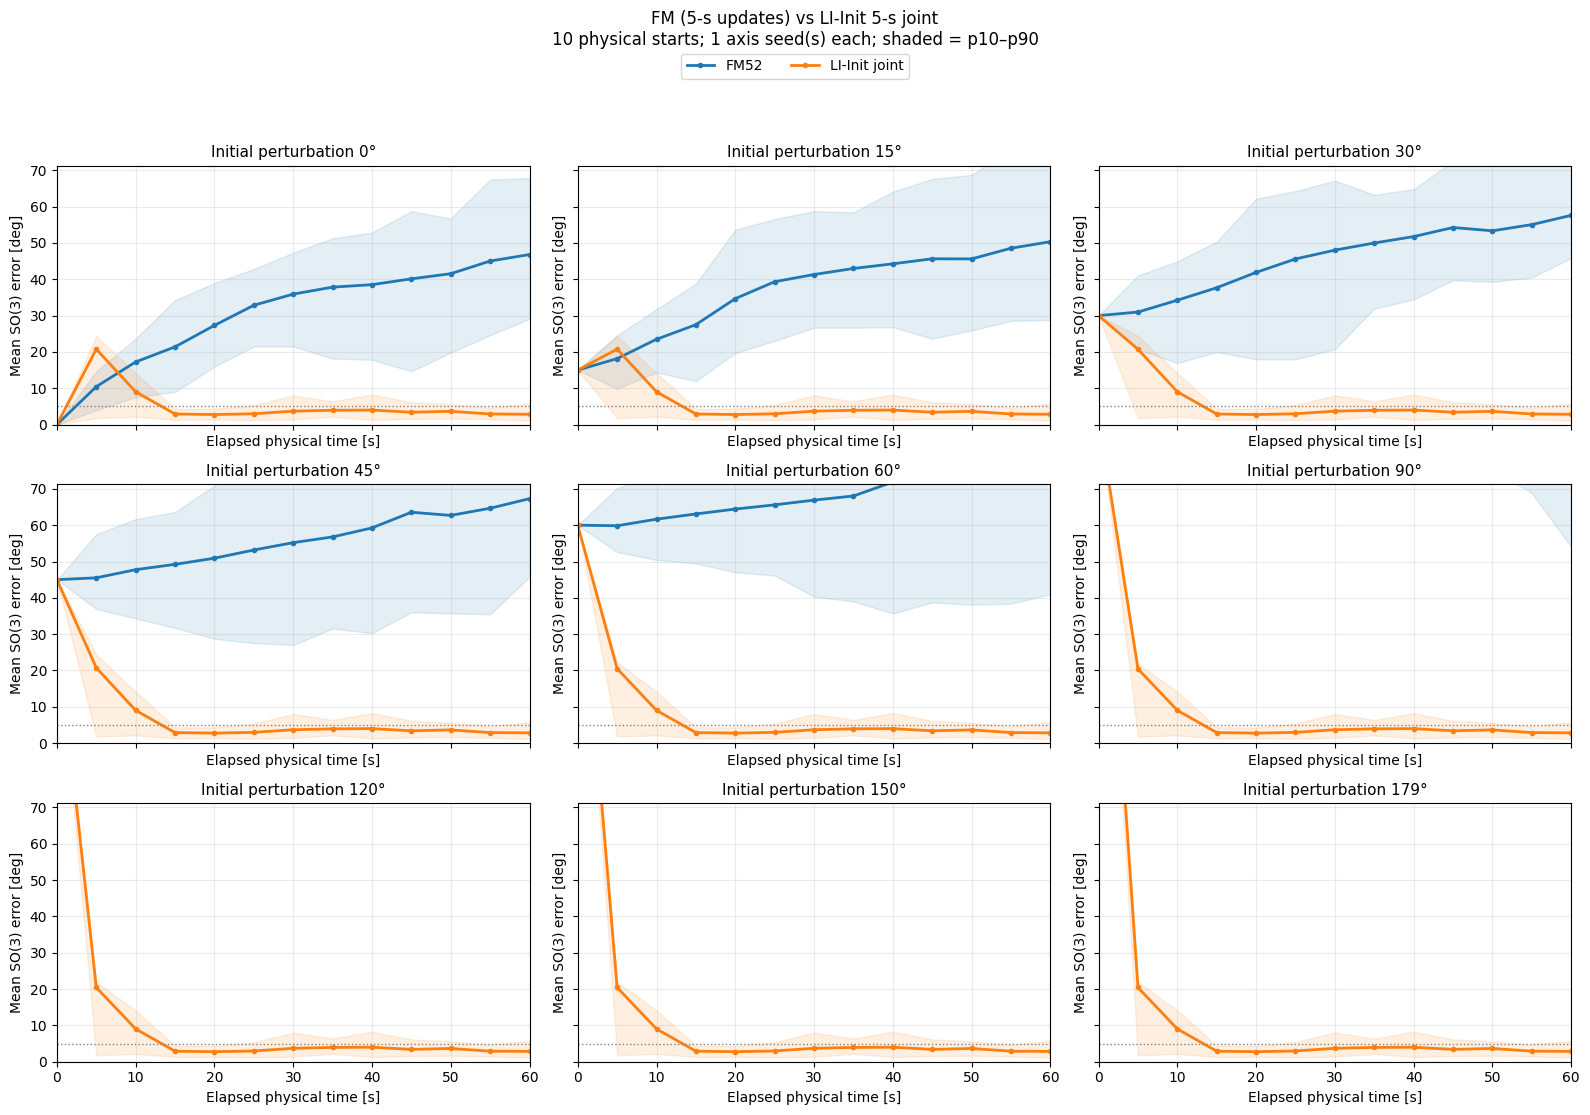

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init/5s_independent_joint_rotation_full.png


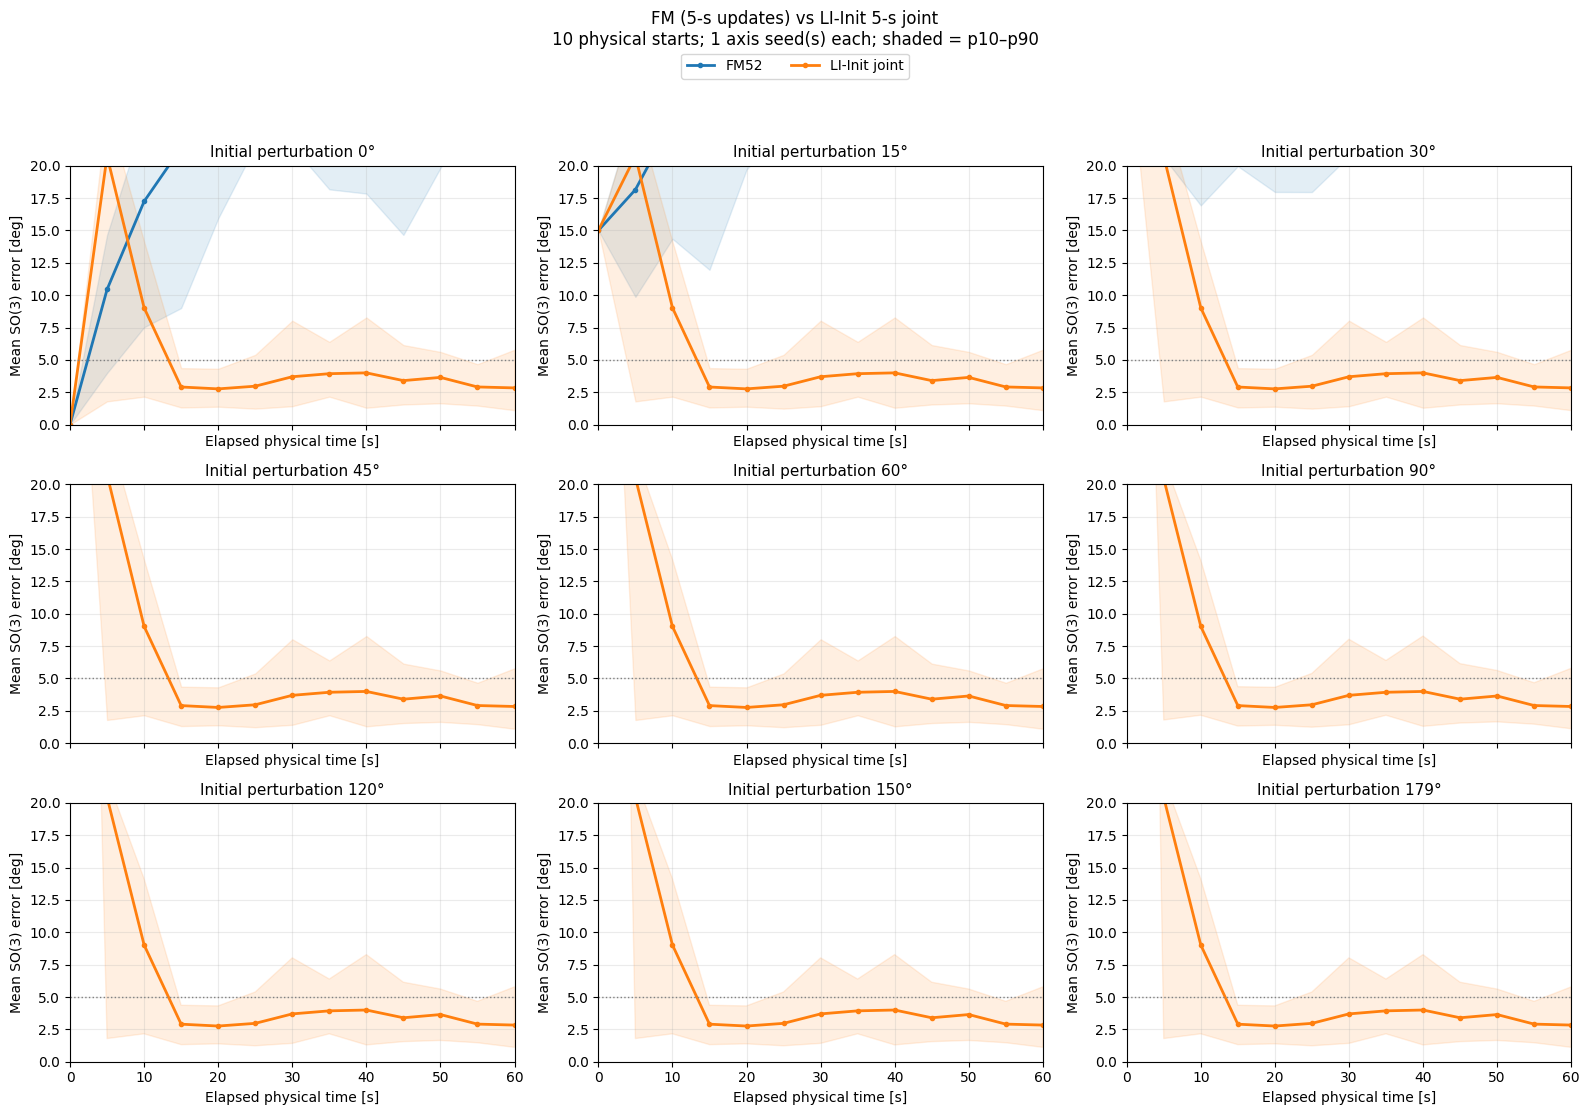

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init/5s_independent_joint_rotation_zoom20deg.png


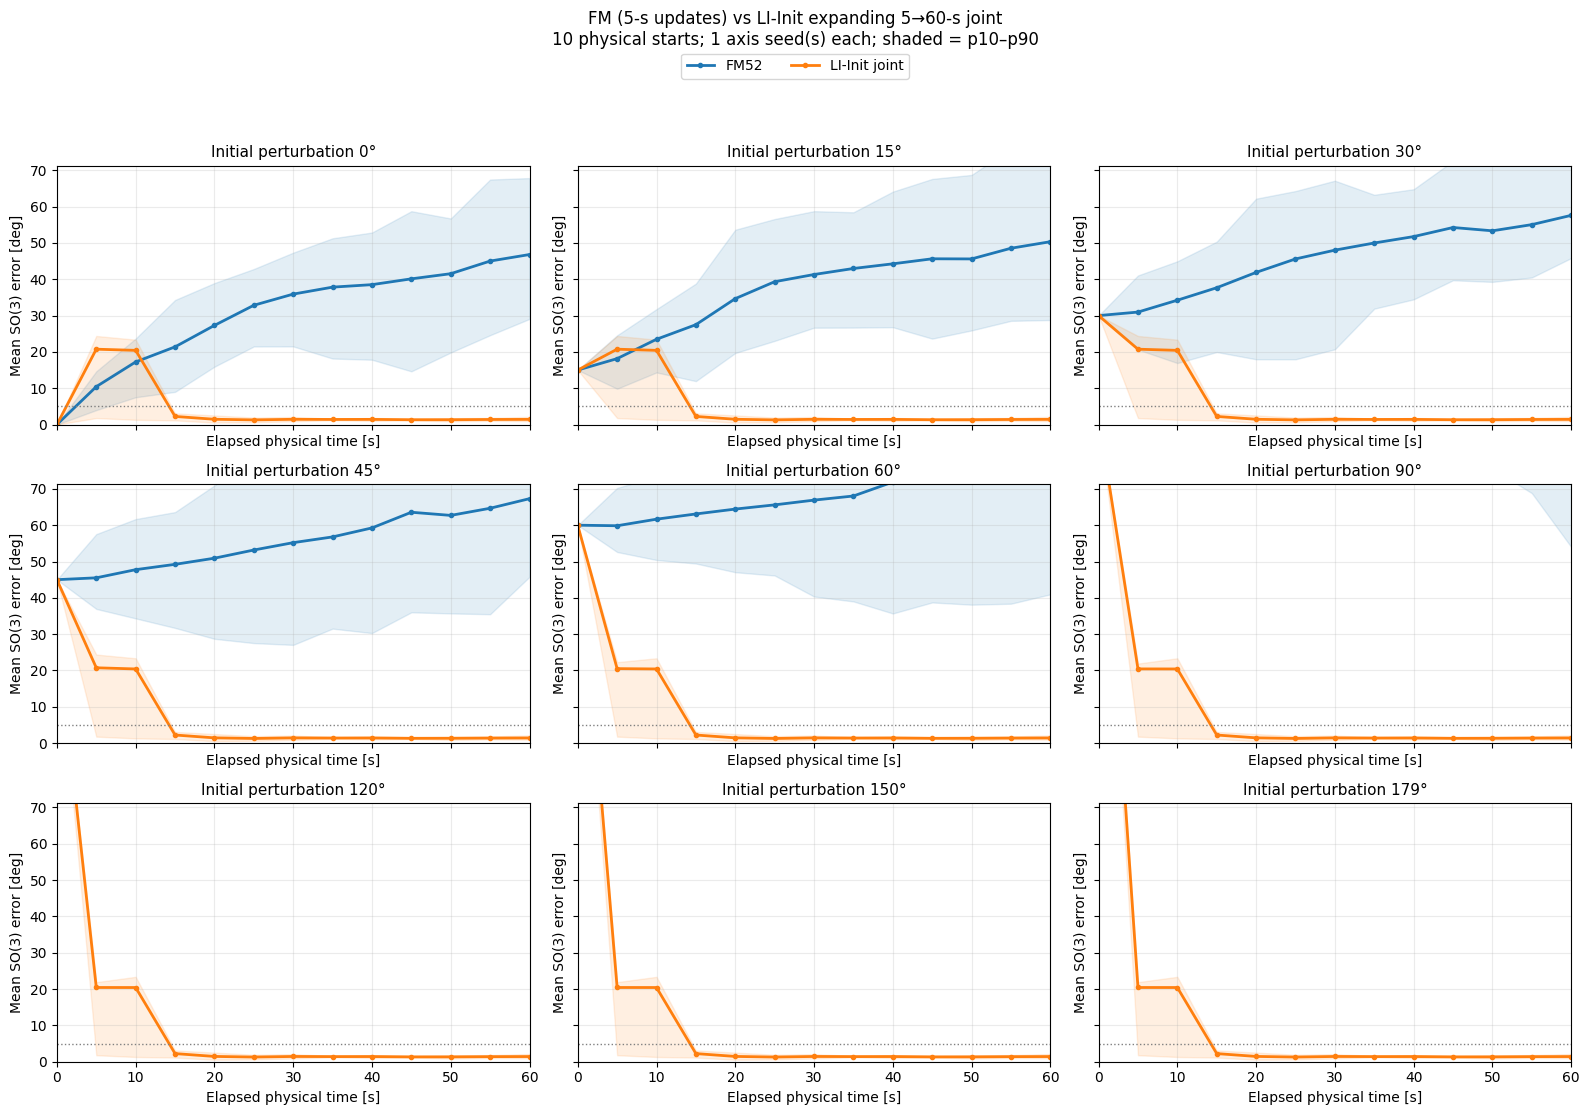

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init/cumulative_up_to_60s_joint_rotation_full.png


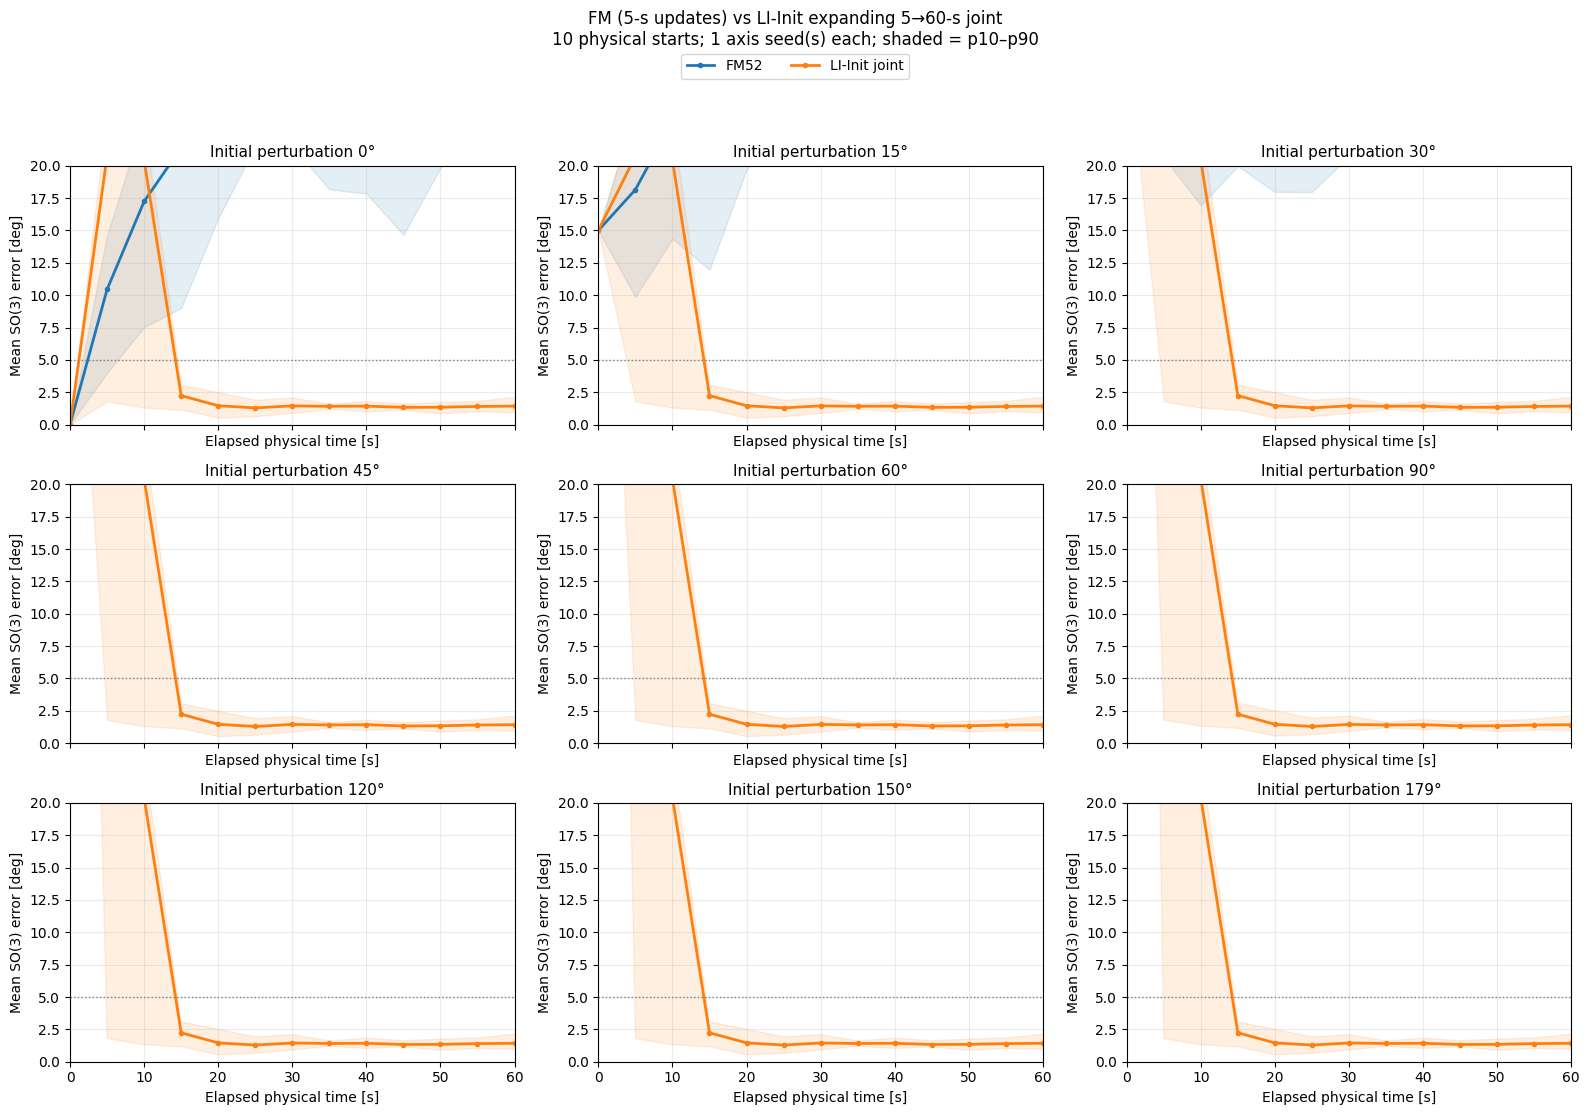

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init/cumulative_up_to_60s_joint_rotation_zoom20deg.png


In [16]:
COLORS = {METHOD_FM: "tab:blue", METHOD_BASELINE: "tab:orange"}
MODE_TITLES = {MODE_5S: "FM (5-s updates) vs LI-Init 5-s joint",
               MODE_60S: "FM (5-s updates) vs LI-Init expanding 5→60-s joint"}


def plot_angle_grid(mode, *, zoom_max=None):
    angles = list(ANGLES_DEG)
    ncols = 3
    nrows = int(np.ceil(len(angles) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.7 * nrows), sharex=True,
                             sharey=zoom_max is None, squeeze=False)
    for ax, angle in zip(axes.flat, angles):
        for method in (METHOD_FM, METHOD_BASELINE):
            part = summary[(summary["mode"] == mode) & (summary["initial_deg"] == angle) & (summary["method"] == method)].sort_values("step")
            x = part.physical_elapsed_s.to_numpy(dtype=float)
            ax.plot(x, part.mean_deg.to_numpy(), color=COLORS[method], marker="o", markersize=3,
                    linewidth=2.0, label=method)
            ax.fill_between(x, part.q10_deg.to_numpy(), part.q90_deg.to_numpy(), color=COLORS[method], alpha=0.12)
        ax.axhline(5.0, linestyle=":", linewidth=1, color="gray")
        ax.set_title(f"Initial perturbation {angle:g}°", fontsize=11)
        ax.set_xlim(0, ROLL_OUT_S)
        ax.set_xticks(np.arange(0, ROLL_OUT_S + 1, 10))
        if zoom_max is not None:
            ax.set_ylim(0, zoom_max)
        else:
            ax.set_ylim(bottom=0)
        ax.grid(alpha=0.25)
        ax.set_xlabel("Elapsed physical time [s]")
        ax.set_ylabel("Mean SO(3) error [deg]")
    for ax in axes.flat[len(angles):]:
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.967), ncol=2)
    fig.suptitle(MODE_TITLES[mode] + f"\n{NUM_STARTS} physical starts; {AXIS_SEEDS} axis seed(s) each; shaded = p10–p90", y=1.00)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    suffix = "full" if zoom_max is None else f"zoom{zoom_max:g}deg"
    path = PLOTS_DIR / f"{mode}_rotation_{suffix}.png"
    fig.savefig(path, dpi=175, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    print("Saved:", path)


for mode in (MODE_5S, MODE_60S):
    plot_angle_grid(mode)
    plot_angle_grid(mode, zoom_max=20.0)

## 13. Paired compute-time comparisons
Wall-clock milliseconds include FM geometry/tokenization/integration and LI-Init temporal estimation/optimization. Neural input caching, disk I/O, and model loading are excluded. **Do not confuse physical time (60 seconds) with computation time (milliseconds).**

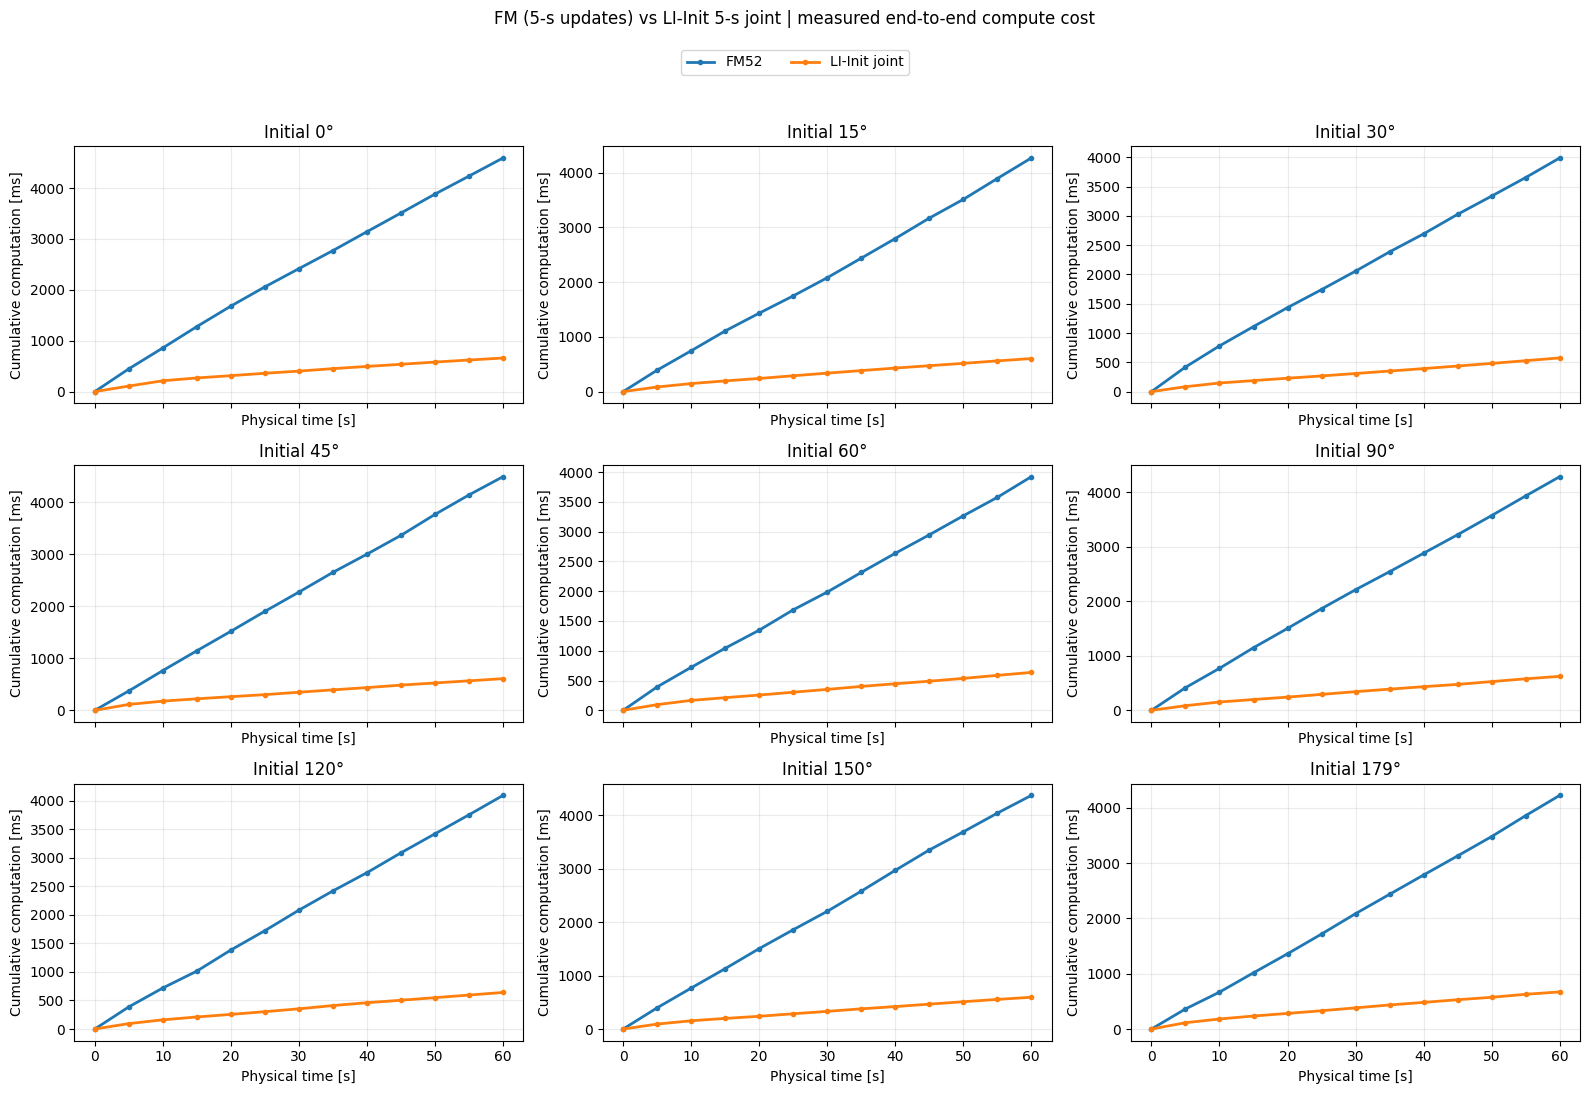

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init/5s_independent_joint_cumulative_runtime.png


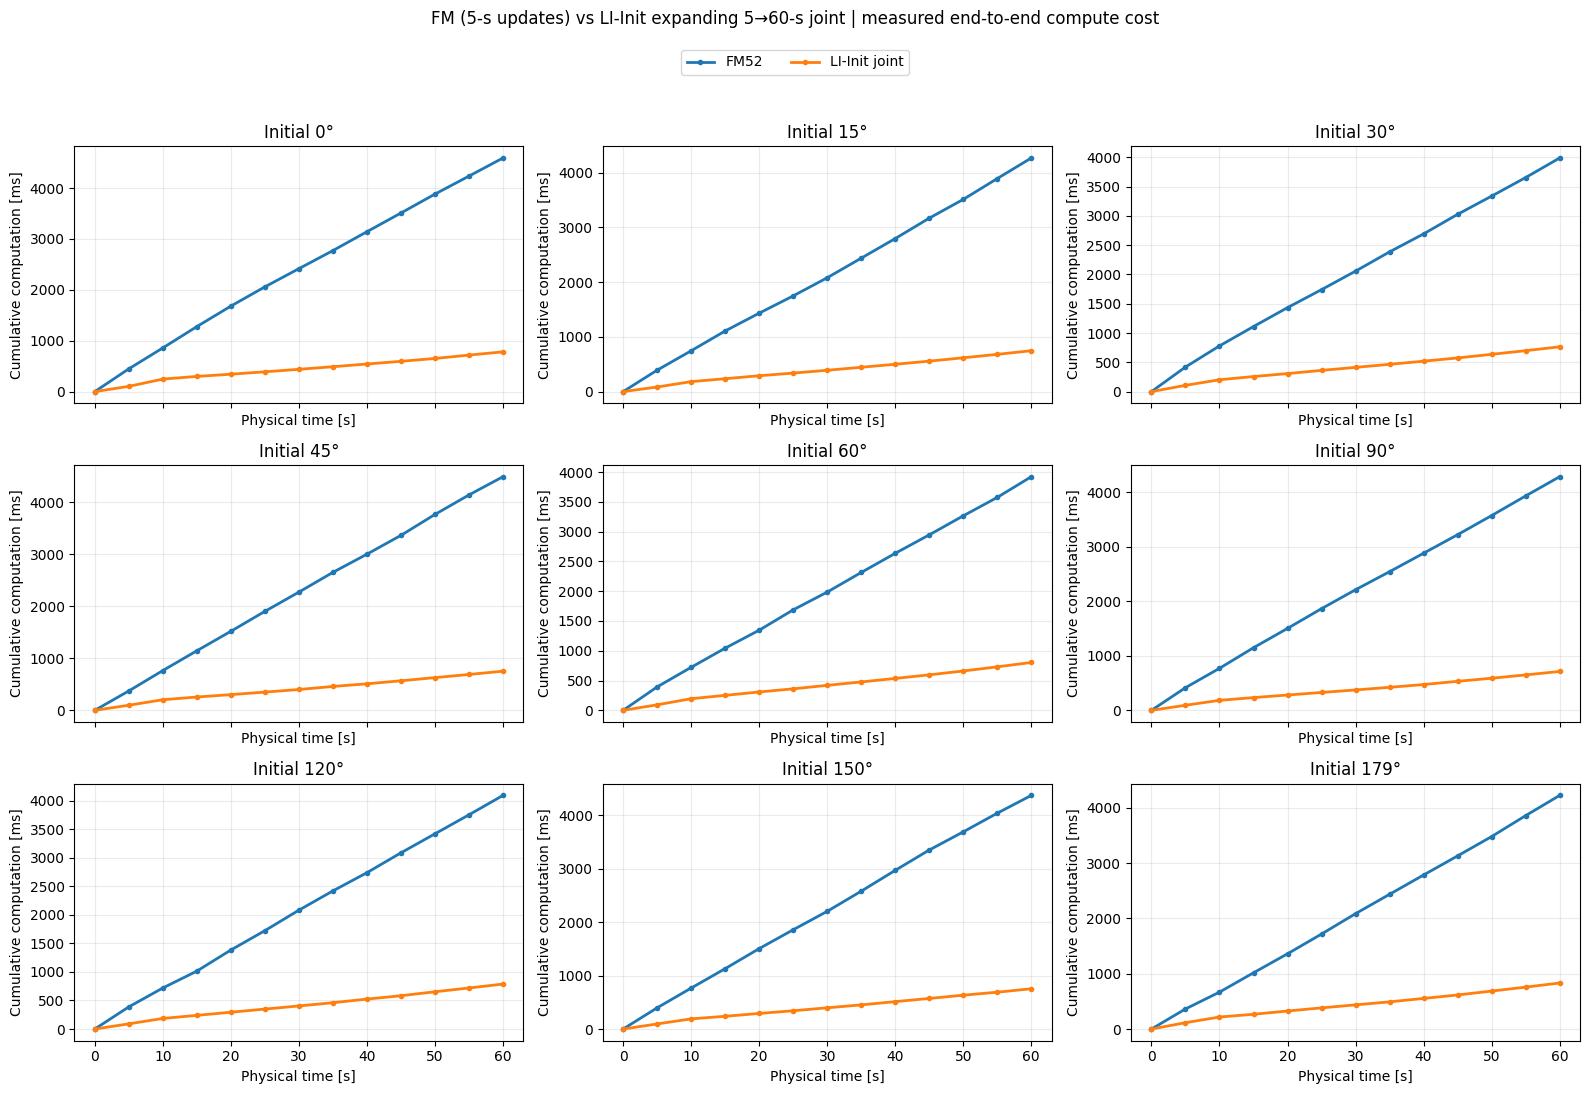

Saved: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init/cumulative_up_to_60s_joint_cumulative_runtime.png


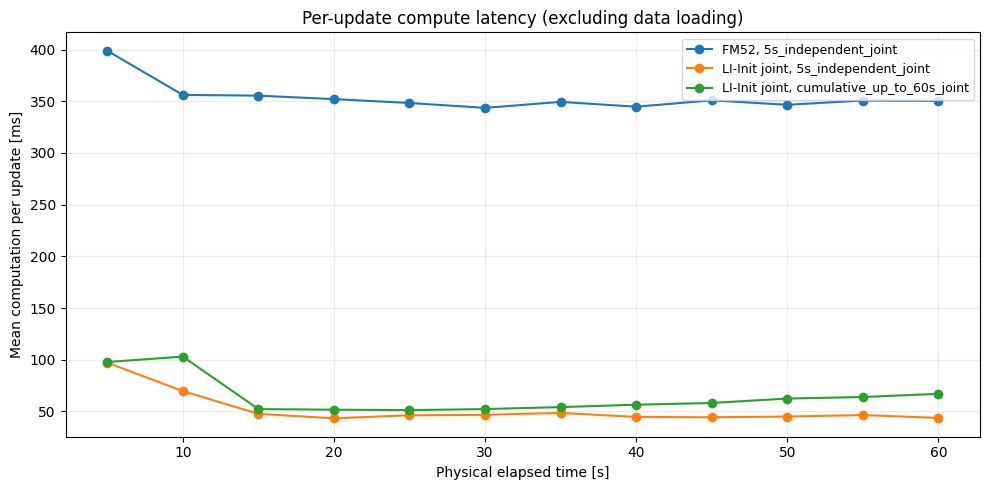

In [17]:
def plot_runtime_grid(mode):
    angles = list(ANGLES_DEG)
    fig, axes = plt.subplots(int(np.ceil(len(angles) / 3)), 3, figsize=(16, 11), sharex=True, squeeze=False)
    for ax, angle in zip(axes.flat, angles):
        for method in (METHOD_FM, METHOD_BASELINE):
            part = summary[(summary["mode"] == mode) & (summary.initial_deg == angle) & (summary.method == method)].sort_values("step")
            ax.plot(part.physical_elapsed_s, part.mean_cumulative_ms, color=COLORS[method], linewidth=2, marker="o",
                    markersize=3, label=method)
        ax.set(title=f"Initial {angle:g}°", xlabel="Physical time [s]", ylabel="Cumulative computation [ms]")
        ax.grid(alpha=0.25)
    for ax in axes.flat[len(angles):]:
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2)
    fig.suptitle(MODE_TITLES[mode] + " | measured end-to-end compute cost", y=0.99)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    path = PLOTS_DIR / f"{mode}_cumulative_runtime.png"
    fig.savefig(path, dpi=175, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)
    print("Saved:", path)


for mode in (MODE_5S, MODE_60S):
    plot_runtime_grid(mode)

# Additionally compare per-update cost across the two numerical modes.
step_cost = (summary[summary.step > 0].groupby(["mode", "method", "step"], as_index=False)
             .agg(mean_ms=("mean_step_ms", "mean"), median_ms=("median_step_ms", "median")))
fig, ax = plt.subplots(figsize=(10, 5))
for (mode, method), part in step_cost.groupby(["mode", "method"]):
    if method == METHOD_FM and mode != MODE_5S:
        continue  # identical FM evaluations in each comparison
    ax.plot(part.step * WINDOW_DURATION_S, part.mean_ms, marker="o", label=f"{method}, {mode}")
ax.set(xlabel="Physical elapsed time [s]", ylabel="Mean computation per update [ms]",
       title="Per-update compute latency (excluding data loading)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "per_update_runtime_comparison.png", dpi=175)
if SHOW_PLOTS: plt.show()
else: plt.close(fig)

## 14. Endpoint accuracy, rollout AUC, and numerical reliability
Report mean/median/p90 errors, fraction below 5°, first recovery time, total compute, and numerical accepted fractions. A converged least-squares solve is not equivalent to a correct extrinsic.

In [18]:
endpoints = rollout_df[rollout_df.step == STEPS].copy()
endpoints["under_5deg"] = endpoints.rotation_error_deg < 5
endpoint_summary = (endpoints.groupby(["mode", "method", "initial_deg"], as_index=False)
                    .agg(n=("rotation_error_deg", "size"), mean_final_deg=("rotation_error_deg", "mean"),
                         median_final_deg=("rotation_error_deg", "median"),
                         p90_final_deg=("rotation_error_deg", q90),
                         success_under_5deg=("under_5deg", "mean"),
                         mean_compute_ms=("total_compute_ms", "mean")))

# Per-run area under error curve and first 5-degree recovery time.
trajectory_summary_rows = []
for (mode, method, start_id, axis_id, angle), group in rollout_df.groupby(
    ["mode", "method", "start_id", "axis_id", "initial_deg"], sort=False):
    group = group.sort_values("step")
    err = group.rotation_error_deg.to_numpy()
    elapsed = group.physical_elapsed_s.to_numpy()
    converged = np.flatnonzero((err < 5.0) & (elapsed > 0))
    trajectory_summary_rows.append(dict(mode=mode, method=method, start_id=start_id,
                                        axis_id=axis_id, initial_deg=angle,
                                        mean_error_over_time_deg=float(trapezoid(err, elapsed) / ROLL_OUT_S),
                                        first_under_5deg_s=float(elapsed[converged[0]]) if len(converged) else np.nan,
                                        final_deg=float(err[-1]),
                                        final_under_5deg=bool(err[-1] < 5),
                                        compute_ms=float(group.total_compute_ms.iloc[-1])))
trajectory_summary = pd.DataFrame(trajectory_summary_rows)
summary_trajectories = (trajectory_summary.groupby(["mode", "method", "initial_deg"], as_index=False)
                        .agg(n=("start_id", "size"), time_mean_error_deg=("mean_error_over_time_deg", "mean"),
                             final_under_5deg=("final_under_5deg", "mean"),
                             first_under_5deg_median_s=("first_under_5deg_s", "median"),
                             compute_median_ms=("compute_ms", "median")))
display(endpoint_summary.round(3))
display(summary_trajectories.round(3))
endpoint_summary.to_csv(OUTPUT_DIR / "fm_vs_li_init_endpoints.csv", index=False)
trajectory_summary.to_csv(OUTPUT_DIR / "fm_vs_li_init_trajectory_runs.csv", index=False)
summary_trajectories.to_csv(OUTPUT_DIR / "fm_vs_li_init_convergence_statistics.csv", index=False)

# See how often the numerical optimization accepted a solution, independently of true error.
accepted = (rollout_df[(rollout_df.method == METHOD_BASELINE) & (rollout_df.step > 0)]
            .groupby(["mode", "initial_deg"], as_index=False)
            .agg(accepted_fraction=("accepted", "mean")))
display(accepted.round(3))

,mode,method,initial_deg,n,mean_final_deg,median_final_deg,p90_final_deg,success_under_5deg,mean_compute_ms
0,5s_independent_joint,FM52,0.0,10,46.809,43.596,67.856,0.0,4591.341
1,5s_independent_joint,FM52,15.0,10,50.340,44.577,73.751,0.0,4264.829
2,5s_independent_joint,FM52,30.0,10,57.592,56.289,76.343,0.0,3989.067
3,5s_independent_joint,FM52,45.0,10,67.304,72.601,88.797,0.0,4490.662
4,5s_independent_joint,FM52,60.0,10,83.476,84.349,122.869,0.0,3922.015
5,5s_independent_joint,FM52,90.0,10,118.235,126.434,163.644,0.0,4285.054
6,5s_independent_joint,FM52,120.0,10,144.239,159.091,166.523,0.0,4090.338
7,5s_independent_joint,FM52,150.0,10,160.333,167.068,173.713,0.0,4371.006
8,5s_independent_joint,FM52,179.0,10,166.289,174.378,177.470,0.0,4222.793
9,5s_independent_joint,LI-Init joint,0.0,10,2.833,1.762,5.784,0.7,660.137


,mode,method,initial_deg,n,time_mean_error_deg,final_under_5deg,first_under_5deg_median_s,compute_median_ms
0,5s_independent_joint,FM52,0.0,10,30.961,0.0,5.0,4610.204
1,5s_independent_joint,FM52,15.0,10,37.008,0.0,NaN,4026.964
2,5s_independent_joint,FM52,30.0,10,45.543,0.0,NaN,3911.213
3,5s_independent_joint,FM52,45.0,10,55.405,0.0,NaN,4261.128
4,5s_independent_joint,FM52,60.0,10,69.055,0.0,NaN,3880.199
5,5s_independent_joint,FM52,90.0,10,106.136,0.0,NaN,4452.347
6,5s_independent_joint,FM52,120.0,10,134.511,0.0,NaN,4147.279
7,5s_independent_joint,FM52,150.0,10,154.635,0.0,NaN,4598.844
8,5s_independent_joint,FM52,179.0,10,169.928,0.0,NaN,4212.561
9,5s_independent_joint,LI-Init joint,0.0,10,5.115,0.7,5.0,517.587


,mode,initial_deg,accepted_fraction
0,5s_independent_joint,0.0,1.0
1,5s_independent_joint,15.0,1.0
2,5s_independent_joint,30.0,1.0
3,5s_independent_joint,45.0,1.0
4,5s_independent_joint,60.0,1.0
5,5s_independent_joint,90.0,1.0
6,5s_independent_joint,120.0,1.0
7,5s_independent_joint,150.0,1.0
8,5s_independent_joint,179.0,1.0
9,cumulative_up_to_60s_joint,0.0,0.991667


## 15. Interpreting the domain transfer

- **Nominal reference, not certified GT.** Calibration was composed from the New College YAML, and camera-frame to fixed Z-up common rotation is shared by all three sensors. Only rotational error is scored.
- **One LiDAR, two IMUs.** FM consumes RealSense + Ouster IMU and Ouster LiDAR; LI-Init pairs Ouster IMU with Ouster LiDAR. The sensor-information asymmetry is deliberate and must be disclosed.
- **No timestamp GT.** The `+0.060 s` effective LiDAR timestamp shift was retained from notebook 45, as a disclosed preprocessing hypothesis. Rerun with `0.000` to test sensitivity; do not compare absolute time-offset errors to an assumed zero.
- **Different optimization horizons.** LI-Init's expanding-history result at 60 seconds is causal. The short-window baseline does not accumulate residuals, only carries its previous estimate as initial state.
- **New College tests generalization.** The same KAIST-trained FM51 checkpoint is used; no retraining, tuning, or changes based on New College labels are made. Do not use these results to choose hyperparameters and then call New College an untouched test set.
- **Per-update latency is hardware dependent.** FM GPU timing is synchronized. Both use roughly the same five-second physical step interval. The expanding solver repeatedly solves longer batches and can be costlier even when its final estimate is better.
- **Scientific reproducibility:** one random axis per start, ten disjoint start intervals. Vary `RANDOM_SEED` or increase `AXIS_SEEDS` for stronger statistics. Failed numerical updates are counted and the old estimate is retained.

**Next controlled tests:** isolate one-step FM refinement of the numerical result, compare using the RealSense IMU as numerical reference, and compare 5-s versus accumulated Wahba initialization without changing sensor observations.

In [19]:
if SAVE_RESULTS:
    print("Results:", OUTPUT_DIR)
    print("Plots:", PLOTS_DIR)
    print("Data rows:", len(rollout_df), "| independent starts:", NUM_STARTS)
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Results: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/newcollege_fm_vs_li_init
Plots: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/plots/newcollege_fm_vs_li_init
Data rows: 4680 | independent starts: 10
